In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("ballon_dor_fbref_dataset_v2.csv")

In [3]:
df.shape

(1930, 71)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1930 entries, 0 to 1929
Data columns (total 71 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Year                          1930 non-null   int64  
 1   Rank                          1930 non-null   float64
 2   Player                        1930 non-null   object 
 3   Club                          1930 non-null   object 
 4   Points                        1815 non-null   float64
 5   match_key                     1930 non-null   object 
 6   rk                            173 non-null    float64
 7   player                        173 non-null    object 
 8   nation                        173 non-null    object 
 9   pos                           173 non-null    object 
 10  squad                         173 non-null    object 
 11  comp                          173 non-null    object 
 12  age                           173 non-null    float64
 13  bor

In [5]:
df.tail(10)

,Year,Rank,Player,Club,Points,match_key,rk,player,nation,pos,...,Total Shots,% Shots on target,Shots p 90,Goals per shot,Goals per shot on target,% Aerial Duels won,Shot creating actions p 90,Goal creating actions p 90,Crosses Stopped,season
1920,2024,21.0,Bukayo Saka,Arsenal,14.0,bukayo saka,2312.0,Bukayo Saka,England,FW,...,102.0,30.4,0.96,0.10,0.32,39.0,5.80,0.65,0.0,2023-2024
1921,2024,22.0,Antonio Rüdiger,Real Madrid,13.0,antonio rudiger,2288.0,Antonio Rüdiger,Germany,DF,...,19.0,10.5,0.07,0.05,0.50,68.1,0.70,0.17,0.0,2023-2024
1922,2024,23.0,Rúben Dias,Manchester City,8.0,ruben dias,700.0,Rúben Dias,Portugal,DF,...,20.0,40.0,0.28,0.00,0.00,52.8,1.23,0.14,0.0,2023-2024
1923,2024,24.0,William Saliba,Arsenal,8.0,william saliba,2318.0,William Saliba,France,DF,...,10.0,30.0,0.08,0.20,0.67,59.5,0.76,0.08,0.0,2023-2024
1924,2024,25.0,Cole Palmer,Chelsea,7.0,cole palmer,2023.0,Cole Palmer,England,FW,...,100.0,37.0,1.28,0.13,0.35,20.0,5.59,0.90,0.0,2023-2024
1925,2024,26.0,Declan Rice,Arsenal,5.0,declan rice,2223.0,Declan Rice,England,MF,...,58.0,34.5,0.56,0.12,0.35,47.6,2.79,0.33,0.0,2023-2024
1926,2024,27.0,Vitinha,Paris Saint-Germain,5.0,vitinha,2721.0,Vitinha,Portugal,MF,...,45.0,42.2,0.80,0.16,0.37,28.6,3.34,0.59,0.0,2023-2024
1927,2024,28.0,Álex Grimaldo,Bayer Leverkusen,2.0,alex grimaldo,1036.0,Álex Grimaldo,Spain,DF,...,71.0,32.4,0.74,0.14,0.43,38.7,4.23,0.68,0.0,2023-2024
1928,2024,29.0,Artem Dovbyk,Girona,0.0,artem dovbyk,764.0,Artem Dovbyk,Ukraine,FW,...,77.0,46.8,1.25,0.22,0.47,49.4,1.98,0.45,0.0,2023-2024
1929,2024,29.0,Mats Hummels,Borussia Dortmund,0.0,mats hummels,1166.0,Mats Hummels,Germany,DF,...,16.0,37.5,0.34,0.19,0.50,61.3,1.37,0.11,0.0,2023-2024


In [6]:
cols_to_drop = ['match_key', 'player', 'rk', 'season']

In [7]:
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

In [8]:
df['Rank'] = df['Rank'].astype(int)

In [9]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' & ', '_and_')
    .str.replace('% ', 'pct_')
    .str.replace(' %', '_pct')
    .str.replace('%', 'pct')
    .str.replace('/', '_per_')
    .str.replace(' ', '_')
)

In [10]:
df['points'] = df['points'].fillna(0)

In [11]:
vini_check = df[df['player'].str.contains("Vinícius|Vinicius", case=False, na=False)]
print("Check 1: Vinícius Júnior Stats")
display(vini_check[['year', 'rank', 'player', 'club', 'goals', 'assists', 'expected_goals']])

Check 1: Vinícius Júnior Stats


,year,rank,player,club,goals,assists,expected_goals
1847,2022,8,Vinícius Júnior,Real Madrid,17.0,10.0,12.3
1875,2023,6,Vinícius Júnior,Real Madrid,10.0,9.0,10.5
1901,2024,2,Vinícius Júnior,Real Madrid,15.0,5.0,13.1


In [12]:
print("\n Check 2: Duplicate Row Count")
print(f"Total Duplicates: {df.duplicated(subset=['year', 'rank', 'player']).sum()}")


 Check 2: Duplicate Row Count
Total Duplicates: 0


In [13]:
modern_missing = df[(df['year'] >= 2018) & (df['goals'].isna())]

In [14]:
print(f"Modern nominees (2018-2024) missing stats: {len(modern_missing)}")

Modern nominees (2018-2024) missing stats: 7


In [15]:
if len(modern_missing) > 0:
    print("\n Players needing name/stat fixes")
    display(modern_missing[['year', 'rank', 'player', 'club']])


 Players needing name/stat fixes


,year,rank,player,club
1790,2019,11,Frenkie de Jong,Ajax Barcelona
1794,2019,15,Matthijs de Ligt,Ajax Juventus
1800,2019,20,Dušan Tadić,Ajax
1807,2019,28,João Félix,Benfica Atlético Madrid
1809,2019,28,Donny van de Beek,Ajax
1852,2022,13,Sébastien Haller,Ajax
1868,2022,25,Darwin Núñez,Benfica


In [16]:
# we dont need to clean these datas cause we have datas of top 5 leagues and these players were outside 
#top 5 leagues or either transferred into middle like De Light and Felix

In [17]:
df.shape

(1930, 67)

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1930 entries, 0 to 1929
Data columns (total 67 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   year                          1930 non-null   int64  
 1   rank                          1930 non-null   int32  
 2   player                        1930 non-null   object 
 3   club                          1930 non-null   object 
 4   points                        1930 non-null   float64
 5   nation                        173 non-null    object 
 6   pos                           173 non-null    object 
 7   squad                         173 non-null    object 
 8   comp                          173 non-null    object 
 9   age                           173 non-null    float64
 10  born                          173 non-null    float64
 11  matches_played                173 non-null    float64
 12  avg_mins_per_match            173 non-null    float64
 13  goa

In [19]:
# Exploratory Data Analysis (EDA)

In [20]:
top_nominated = df['player'].value_counts().head(5) #(Most Time the player has been nominated)

In [21]:
top_3_finishes = df[df['rank'] <= 3]['player'].value_counts().head(5)

In [22]:
top_clubs = df['club'].value_counts().head(5)

In [23]:
top_nominated

player
Cristiano Ronaldo    18
Lionel Messi         16
Johan Cruijff        12
Franz Beckenbauer    12
Michel Platini       11
Name: count, dtype: int64

In [24]:
top_3_finishes

player
Lionel Messi         14
Cristiano Ronaldo    12
Michel Platini        5
Franz Beckenbauer     5
Raymond Kopa          4
Name: count, dtype: int64

In [25]:
top_clubs

club
Real Madrid CF    149
FC Barcelona      127
Juventus          110
Bayern Munich     107
Milan              93
Name: count, dtype: int64

In [26]:
#Visualization

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
sns.set_theme(style="whitegrid")

In [29]:
top_10_clubs = df['club'].value_counts().head(10)

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\3384693719.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_clubs.values, y=top_10_clubs.index, palette="viridis")


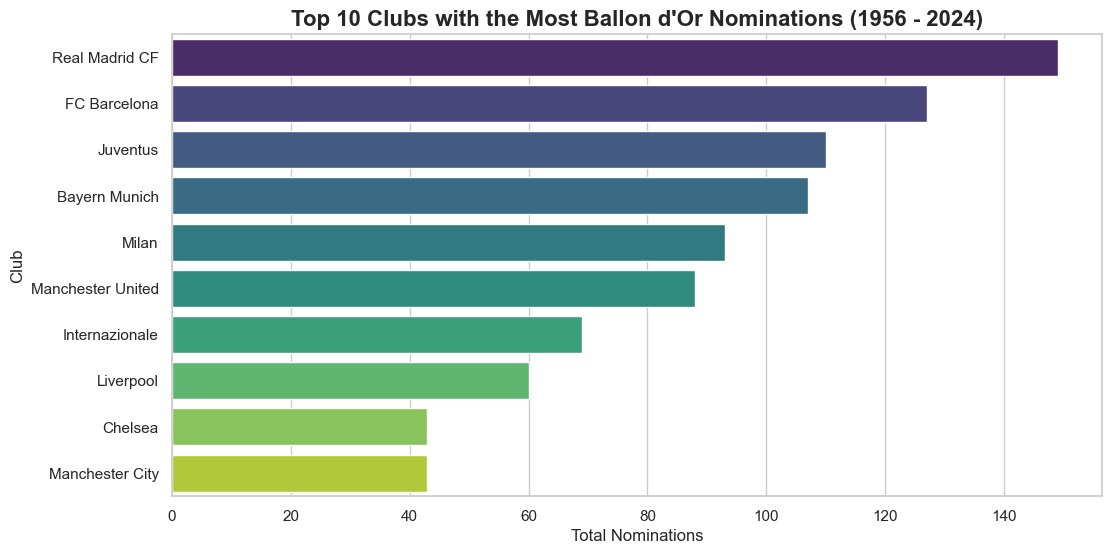

In [30]:
plt.figure(figsize=(12, 6))
plt.title("Top 10 Clubs with the Most Ballon d'Or Nominations (1956 - 2024)", fontsize=16, fontweight='bold')
plt.xlabel("Total Nominations", fontsize=12)
plt.ylabel("Club", fontsize=12)
sns.barplot(x=top_10_clubs.values, y=top_10_clubs.index, palette="viridis")
plt.show()

In [31]:
modern_df = df[df['year'] >= 2018].copy()

In [32]:
key_stats = [
    'rank', 'points', 'goals', 'assists',
    'expected_goals', 'progressive_passes',
    'shot_creating_actions_p_90', 'clean_sheets'
]

In [33]:
corr_matrix = modern_df[key_stats].corr()

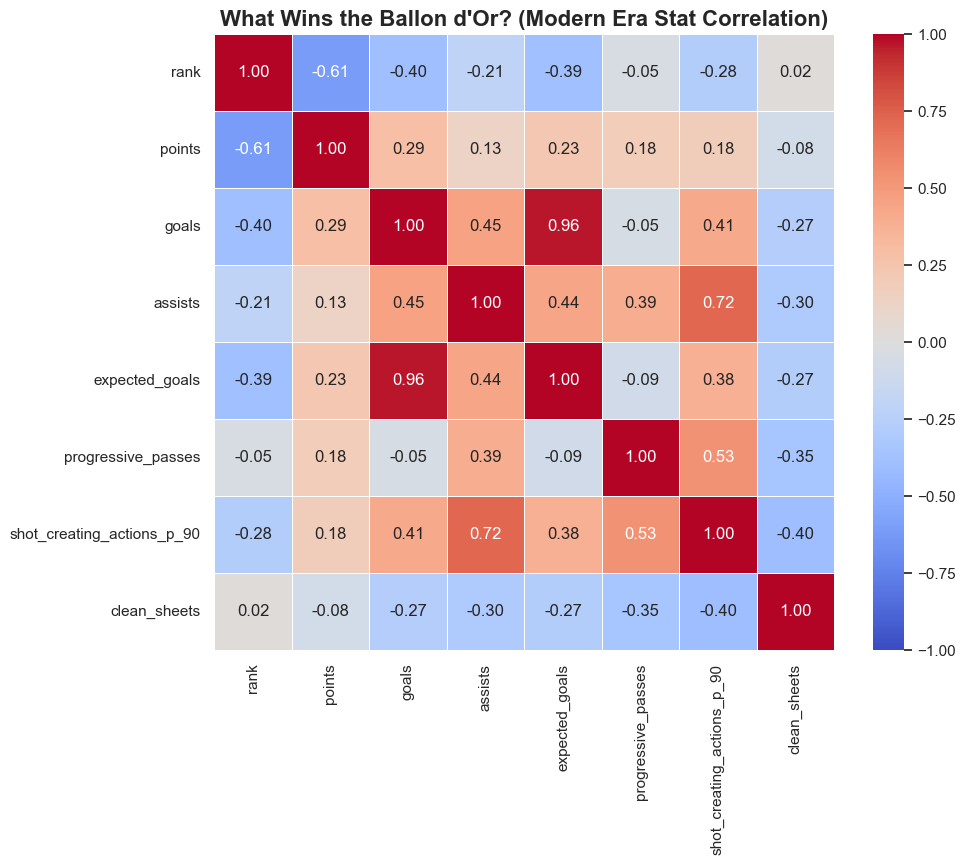

In [34]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,          # Shows the actual numbers in the squares
    cmap='coolwarm',     
    fmt=".2f",           # Rounds to 2 decimal places
    linewidths=0.5,
    vmin=-1, vmax=1
)

plt.title("What Wins the Ballon d'Or? (Modern Era Stat Correlation)", fontsize=16, fontweight='bold')
plt.show()

In [35]:
from adjustText import adjust_text

In [36]:
# plt.figure(figsize=(13, 7))

# sns.scatterplot(
#     data=modern_df,
#     x='goals',
#     y='rank',
#     hue='points',
#     palette='viridis',     # Clean modern color palette
#     size='points',
#     sizes=(40, 500),
#     alpha=0.85,
#     edgecolor='black',
#     linewidth=0.5
# )

# plt.ylim(31, -3)
# plt.gca().invert_yaxis()

# winners = modern_df[modern_df['rank'] == 1]
# texts = []

# for index, row in winners.iterrows():
#     # Extract last name cleanly (e.g., "Messi", "Rodri", "Benzema")
#     last_name = row['player'].split()[-1].title()
#     short_year = str(row['year'])[-2:]
#     label = f"{last_name} ('{short_year})"

#     texts.append(
#         plt.text(
#             row['goals'],
#             row['rank'],
#             label,
#             fontsize=11,
#             fontweight='bold',
#             color='black'
#         )
#     )

# adjust_text(
#     texts,
#     expand_text=(1.5, 1.8),
#     arrowprops=dict(arrowstyle="->", color='black', lw=1)
# )

# avg_goals = modern_df['goals'].mean()
# plt.axvline(avg_goals, color='red', linestyle='--', alpha=0.6, label=f'Avg Goals ({avg_goals:.1f})')

# plt.title("Ballon d'Or Winners vs. Season Goals (2018 - 2024)", fontsize=16, fontweight='bold', pad=15)
# plt.xlabel("Total Goals Scored", fontsize=12)
# plt.ylabel("Ballon d'Or Rank (1 = Winner)", fontsize=12)

# plt.legend(title="Voting Points", bbox_to_anchor=(1.02, 1), loc='upper left')
# plt.tight_layout()

# plt.figure(figsize=(13, 7))

# sns.scatterplot(
#     data=modern_df,
#     x='goals',
#     y='rank',
#     hue='points',
#     palette='viridis',     # Clean modern color palette
#     size='points',
#     sizes=(40, 500),
#     alpha=0.85,
#     edgecolor='black',
#     linewidth=0.5
# )

# plt.ylim(31, -3)
# plt.gca().invert_yaxis()

# winners = modern_df[modern_df['rank'] == 1]
# texts = []

# for index, row in winners.iterrows():
#     # Extract last name cleanly (e.g., "Messi", "Rodri", "Benzema")
#     last_name = row['player'].split()[-1].title()
#     short_year = str(row['year'])[-2:]
#     label = f"{last_name} ('{short_year})"

#     texts.append(
#         plt.text(
#             row['goals'],
#             row['rank'],
#             label,
#             fontsize=11,
#             fontweight='bold',
#             color='black'
#         )
#     )

# adjust_text(
#     texts,
#     expand_text=(1.5, 1.8),
#     arrowprops=dict(arrowstyle="->", color='black', lw=1)
# )

# avg_goals = modern_df['goals'].mean()
# plt.axvline(avg_goals, color='red', linestyle='--', alpha=0.6, label=f'Avg Goals ({avg_goals:.1f})')

# plt.title("Ballon d'Or Winners vs. Season Goals (2018 - 2024)", fontsize=16, fontweight='bold', pad=15)
# plt.xlabel("Total Goals Scored", fontsize=12)
# plt.ylabel("Ballon d'Or Rank (1 = Winner)", fontsize=12)

# plt.legend(title="Voting Points", bbox_to_anchor=(1.02, 1), loc='upper left')
# plt.tight_layout()



Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


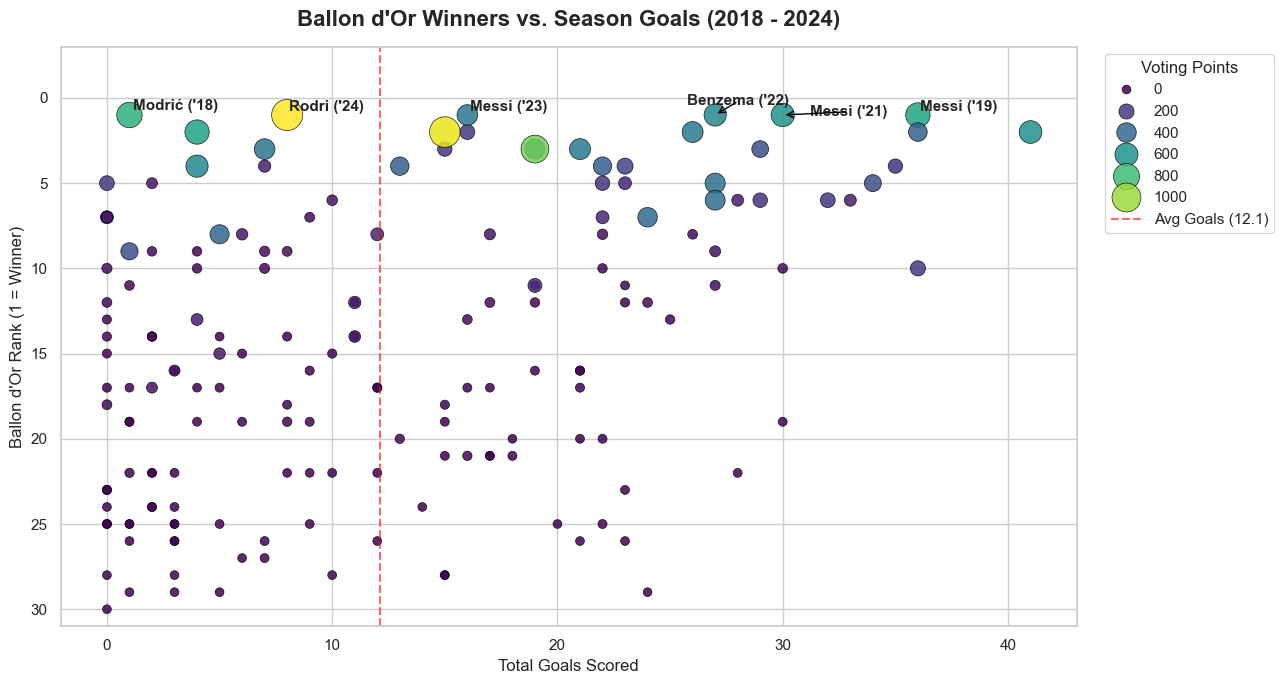

In [37]:
plt.figure(figsize=(13, 7))

# 1. Scatterplot remains mostly the same (kept your clean styling)
sns.scatterplot(
    data=modern_df, x='goals', y='rank', hue='points', palette='viridis',
    size='points', sizes=(40, 500), alpha=0.85, edgecolor='black', linewidth=0.5
)

# 2. Fixed axis inversion (using both ylim(31, -3) and invert_yaxis() was redundant)
plt.ylim(31, -3)

# 3. Condensed the 10-line 'for' loop into a single list comprehension
winners = modern_df[modern_df['rank'] == 1]
texts = [
    plt.text(row['goals'], row['rank'], f"{row['player'].split()[-1].title()} ('{str(row['year'])[-2:]})", 
             fontsize=11, weight='bold') for _, row in winners.iterrows()
]

# 4. Adjust text
adjust_text(texts, expand_text=(1.5, 1.8), arrowprops=dict(arrowstyle="->", color='black', lw=1))

# 5. Condensed formatting (used 'ls' instead of 'linestyle', combined labels)
avg_goals = modern_df['goals'].mean()
plt.axvline(avg_goals, color='red', ls='--', alpha=0.6, label=f'Avg Goals ({avg_goals:.1f})')

plt.title("Ballon d'Or Winners vs. Season Goals (2018 - 2024)", fontsize=16, weight='bold', pad=15)
plt.xlabel("Total Goals Scored", fontsize=12)
plt.ylabel("Ballon d'Or Rank (1 = Winner)", fontsize=12)

plt.legend(title="Voting Points", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

In [38]:
# We grab the first two letters of the 'pos' column to find their main role
modern_df['primary_pos'] = modern_df['pos'].astype(str).str[:2]

In [39]:
pos_mapping = {
    'FW': 'Forward',
    'MF': 'Midfielder',
    'DF': 'Defender',
    'GK': 'Goalkeeper'
}

In [40]:
modern_df['position_name'] = modern_df['primary_pos'].map(pos_mapping)

In [41]:
# Drop anyone who didn't have a position listed just to be safe
plot_df = modern_df.dropna(subset=['position_name'])

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\3434088489.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\user1\AppData\Local\Temp\ipykernel_3992\3434088489.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


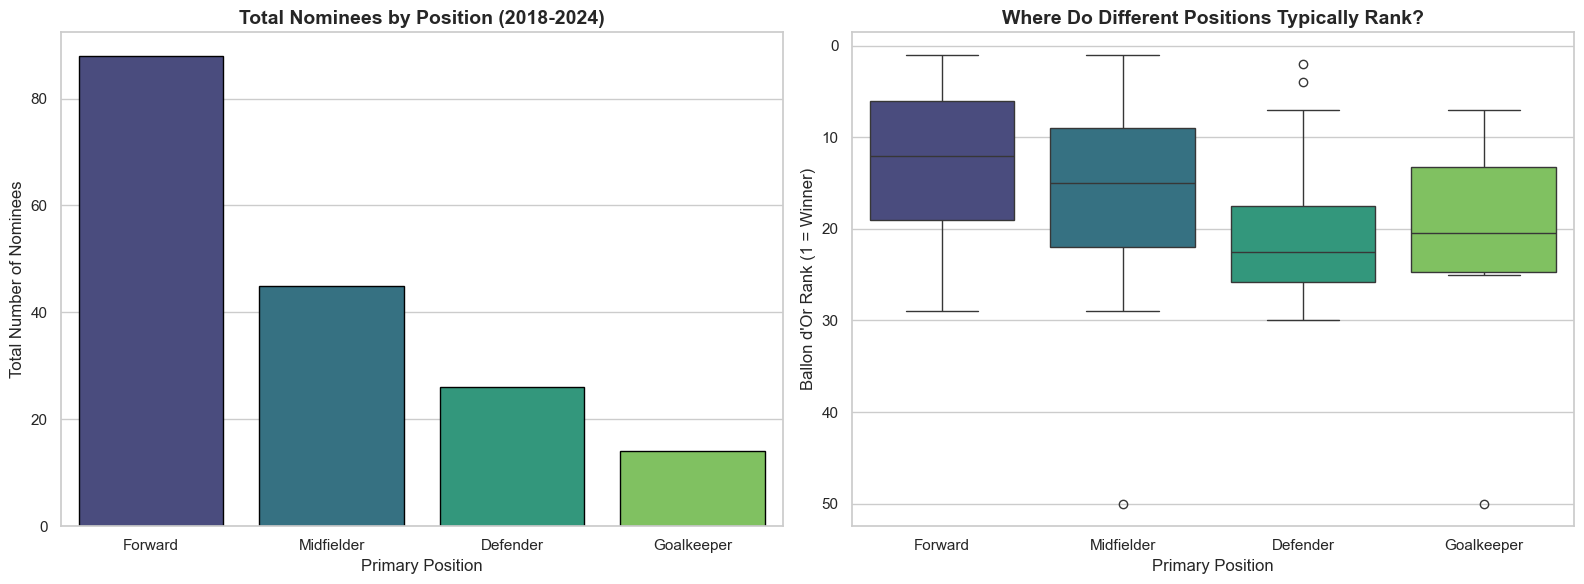

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# --- CHART 1: Total Nominations by Position ---
sns.countplot(
    data=plot_df,
    x='position_name',
    order=['Forward', 'Midfielder', 'Defender', 'Goalkeeper'],
    palette='viridis',
    ax=axes[0],
    edgecolor='black'
)
axes[0].set_title("Total Nominees by Position (2018-2024)", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Primary Position", fontsize=12)
axes[0].set_ylabel("Total Number of Nominees", fontsize=12)

# --- CHART 2: Rank Distribution by Position (Box Plot) ---
sns.boxplot(
    data=plot_df,
    x='position_name',
    y='rank',
    order=['Forward', 'Midfielder', 'Defender', 'Goalkeeper'],
    palette='viridis',
    ax=axes[1]
)
# Invert the Y-axis so Rank 1 is sitting at the very top of the box plot!
axes[1].invert_yaxis()
axes[1].set_title("Where Do Different Positions Typically Rank?", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Primary Position", fontsize=12)
axes[1].set_ylabel("Ballon d'Or Rank (1 = Winner)", fontsize=12)

plt.tight_layout()
plt.show()

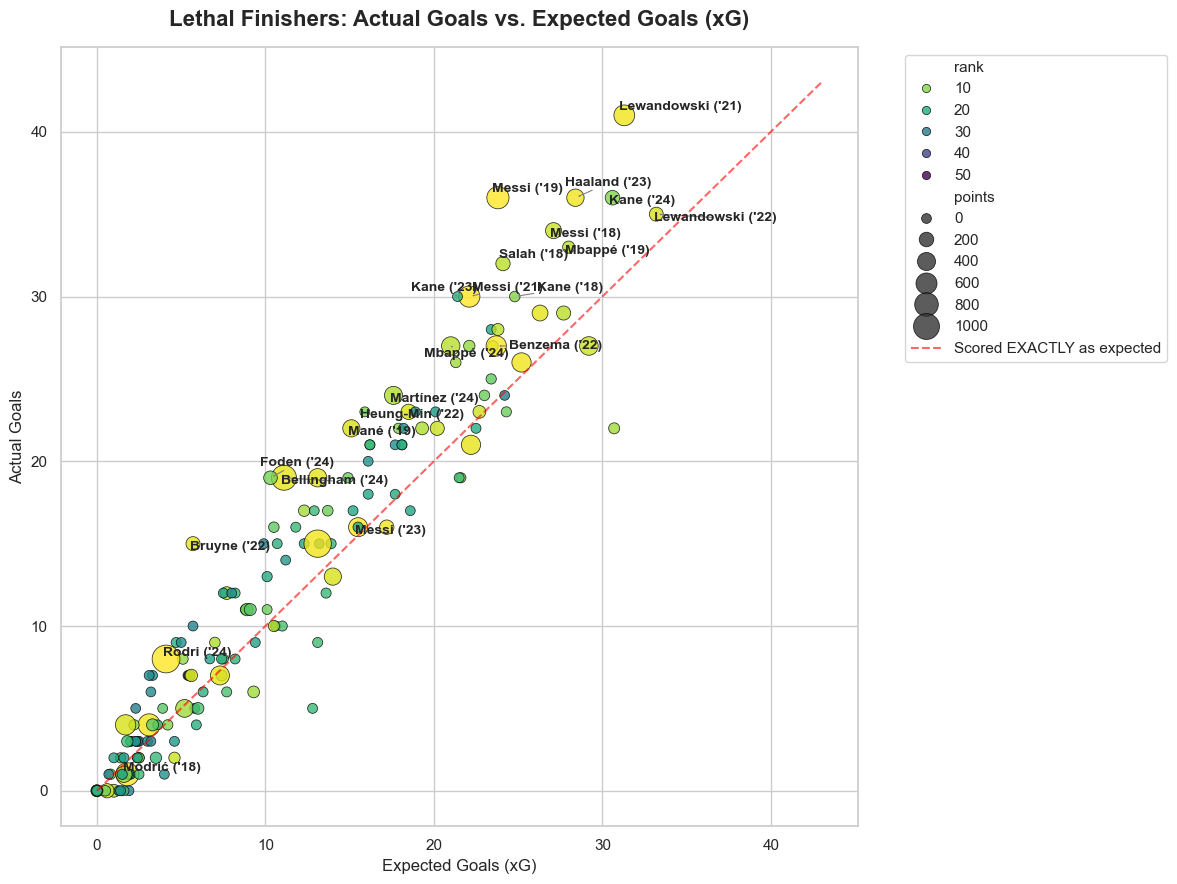

In [43]:
plt.figure(figsize=(12, 9))

# 1. Build the base Scatter Plot
sns.scatterplot(
    data=modern_df,
    x='expected_goals',
    y='goals',
    hue='rank',
    palette='viridis_r',
    size='points',
    sizes=(50, 400),
    alpha=0.8,
    edgecolor='black'
)

# 2. Draw the "Equality Line" (Expected = Actual)
max_val = max(modern_df['goals'].max(), modern_df['expected_goals'].max()) + 2
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', alpha=0.6, label='Scored EXACTLY as expected')

# 3. Smart Labeling Logic
texts = []
# Drop NaNs just for the loop so it doesn't break when doing math
for index, row in modern_df.dropna(subset=['goals', 'expected_goals']).iterrows():

    # Calculate how much they overperformed
    overperformance = row['goals'] - row['expected_goals']

    # THE GOLDILOCKS RULE: Only label the freaks and the winners
    if row['goals'] >= 30 or overperformance >= 6 or row['rank'] == 1:
        last_name = str(row['player']).split()[-1].title()
        short_year = str(row['year'])[-2:]

        texts.append(
            plt.text(
                row['expected_goals'],
                row['goals'],
                f"{last_name} ('{short_year})",
                fontsize=10,
                fontweight='bold'
            )
        )

# 4. Magically space out the few labels we kept
adjust_text(texts, arrowprops=dict(arrowstyle="->", color='gray', lw=0.8))

# 5. Titles and Labels
plt.title("Lethal Finishers: Actual Goals vs. Expected Goals (xG)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Expected Goals (xG)", fontsize=12)
plt.ylabel("Actual Goals", fontsize=12)

# Move legend outside
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

In [44]:
#Feature Engineering

In [45]:
modern_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 180 entries, 1750 to 1929
Data columns (total 69 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   year                          180 non-null    int64  
 1   rank                          180 non-null    int32  
 2   player                        180 non-null    object 
 3   club                          180 non-null    object 
 4   points                        180 non-null    float64
 5   nation                        173 non-null    object 
 6   pos                           173 non-null    object 
 7   squad                         173 non-null    object 
 8   comp                          173 non-null    object 
 9   age                           173 non-null    float64
 10  born                          173 non-null    float64
 11  matches_played                173 non-null    float64
 12  avg_mins_per_match            173 non-null    float64
 13  goals 

In [46]:
modern_df['goal_contributions_p_90'] = modern_df['goals_p_90'] + modern_df['assists_p_90']

In [47]:
modern_df['xg_overperformance'] = modern_df['goals'] - modern_df['expected_goals']

In [48]:
#One hot encoding

In [49]:
position_dummies = pd.get_dummies(modern_df['position_name'], prefix='is')

In [50]:
modern_df = pd.concat([modern_df, position_dummies], axis=1)

In [51]:
columns_to_show = ['player', 'rank', 'goal_contributions_p_90', 'xg_overperformance', 'is_Forward']
modern_df[columns_to_show].head()

,player,rank,goal_contributions_p_90,xg_overperformance,is_Forward
1750,Luka Modrić,1,0.32,-0.8,False
1751,Cristiano Ronaldo,2,1.22,0.8,True
1752,Antoine Griezmann,3,1.00,5.9,True
1753,Kylian Mbappé,4,0.90,-1.0,True
1754,Lionel Messi,5,1.38,6.9,True


In [52]:
modern_df[modern_df['year'] == 2024][columns_to_show].head()

,player,rank,goal_contributions_p_90,xg_overperformance,is_Forward
1900,Rodri,1,0.53,3.9,False
1901,Vinícius Júnior,2,0.96,1.9,True
1902,Jude Bellingham,3,0.97,7.9,False
1903,Dani Carvajal,4,0.29,2.3,False
1904,Erling Haaland,5,1.13,-2.2,True


In [53]:
correlation_features = [
    'rank',
    'goals', 'assists', 'expected_goals',
    'goal_contributions_p_90', 'xg_overperformance',
    'is_Forward', 'is_Midfielder', 'is_Defender'
]

In [54]:
print("(Remember: A stronger negative number means it pushes you closer to Rank 1!)\n")
modern_df[correlation_features].corr()[['rank']].sort_values(by='rank')

(Remember: A stronger negative number means it pushes you closer to Rank 1!)



,rank
goals,-0.396802
goal_contributions_p_90,-0.393171
expected_goals,-0.390572
is_Forward,-0.306304
xg_overperformance,-0.211758
assists,-0.206497
is_Midfielder,0.020271
is_Defender,0.245324
rank,1.000000


In [55]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

In [56]:
features = [
    'goals', 'assists', 'expected_goals',
    'goal_contributions_p_90', 'xg_overperformance',
    'is_Forward', 'is_Midfielder', 'is_Defender'
]

target = 'rank'

In [57]:
ml_df = modern_df.dropna(subset=features + [target])

In [58]:
X = ml_df[features]
y = ml_df[target]

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [60]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [61]:
predictions = model.predict(X_test)

In [62]:
mae = mean_absolute_error(y_test, predictions)

In [63]:
print(f"On average, the model's prediction is off by {mae:.2f} ranks.")

On average, the model's prediction is off by 7.65 ranks.


In [64]:
importances = model.feature_importances_

In [65]:
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\618347047.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance_df, x='Importance', y='Feature', palette='viridis')


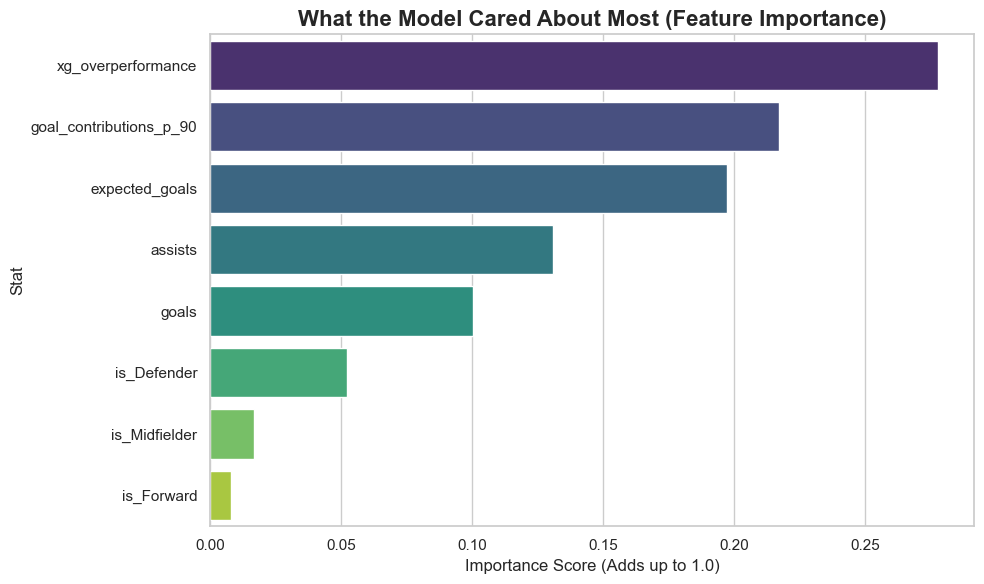

In [66]:
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df, x='Importance', y='Feature', palette='viridis')
plt.title("What the Model Cared About Most (Feature Importance)", fontsize=16, fontweight='bold')
plt.xlabel("Importance Score (Adds up to 1.0)", fontsize=12)
plt.ylabel("Stat", fontsize=12)
plt.tight_layout()

In [67]:
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [68]:
models = {
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
}

In [69]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    results.append({"Model": name, "Mean Absolute Error (MAE)": round(mae, 2)})

In [70]:
results_df = pd.DataFrame(results).sort_values(by="Mean Absolute Error (MAE)")
print("MODEL PERFORMANCES")
display(results_df)

MODEL PERFORMANCES


,Model,Mean Absolute Error (MAE)
0,Random Forest,7.65
2,XGBoost,7.83
1,Gradient Boosting,8.15


In [71]:
#So we choose Random Forest Model for our Balondor Predictor

In [72]:
#Adding Defensive Features to trying to reduce MAE

In [73]:
features_opt2 = [
    'goals', 'assists', 'expected_goals',
    'goal_contributions_p_90', 'xg_overperformance',
    'is_Forward', 'is_Midfielder', 'is_Defender',
    # --- New Defensive Stats ---
    'clean_sheets', 'interceptions', 'clearances', 'tackles_won'
]

In [74]:
df_opt2 = modern_df.dropna(subset=features_opt2 + [target]).copy()

In [75]:
X_def = df_opt2[features_opt2]
y_def = df_opt2[target]

In [76]:
X_train_def, X_test_def, y_train_def, y_test_def = train_test_split(X_def, y_def, test_size=0.2, random_state=42)

In [77]:
rf_model_def = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_def.fit(X_train_def, y_train_def)

RandomForestRegressor(random_state=42)

In [78]:
preds_def = rf_model_def.predict(X_test_def)
mae_def = mean_absolute_error(y_test_def, preds_def)

In [79]:
print(f"New Model Evaluation (With Defensive Stats):")
print(f"On average, the prediction is now off by {mae_def:.2f} ranks.")

New Model Evaluation (With Defensive Stats):
On average, the prediction is now off by 7.58 ranks.


In [80]:
# So we have kinda decrease the MAE from 7.65 to 7.58 but its negligible

In [81]:
#So now we will be trying to add UCL, Leagues and Other International Tournament Datas to try to decrease the MAE

In [82]:
import re
import requests

In [83]:
#1. Helper function to clean Wikipedia's annoying footnotes (e.g., "Real Madrid[a]" -> "Real Madrid")
def clean_wiki_text(text):
    if pd.isna(text): return str(text)
    return re.sub(r'\[.*?\]|\(.*?\)|\*', '', str(text)).strip()

In [84]:
#Scraping UCL Datas

In [85]:
ucl_url = "https://en.wikipedia.org/wiki/List_of_European_Cup_and_UEFA_Champions_League_finals"
print(f"Scraping UCL data from: {ucl_url}")

Scraping UCL data from: https://en.wikipedia.org/wiki/List_of_European_Cup_and_UEFA_Champions_League_finals


In [86]:
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"
}

In [87]:
response = requests.get(ucl_url, headers=headers)

In [88]:
ucl_tables = pd.read_html(response.text)

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\3899820081.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  ucl_tables = pd.read_html(response.text)


In [89]:
# find the correct table (the one with 'Winners' and 'Runners-up')
for table in ucl_tables:
    if isinstance(table.columns, pd.MultiIndex):
        table.columns = table.columns.get_level_values(-1)

    if 'Winners' in table.columns and 'Runners-up' in table.columns:
        ucl_data = table
        break

In [90]:
ucl_data = ucl_data[['Season', 'Winners', 'Runners-up']].dropna()
ucl_data['Winners'] = ucl_data['Winners'].apply(clean_wiki_text)
ucl_data['Runners-up'] = ucl_data['Runners-up'].apply(clean_wiki_text)

In [91]:
# Grab the first 4 characters (the starting year) and add 1
# E.g., "2023-24" -> 2023 + 1 = 2024..
ucl_data['Year'] = ucl_data['Season'].str[:4].astype(int) + 1

In [92]:
modern_ucl = ucl_data[ucl_data['Year'] >= 2018].copy()

In [93]:
modern_ucl.head(10)

,Season,Winners,Runners-up,Year
63,2017–18,Real Madrid,Liverpool,2018
64,2018–19,Liverpool,Tottenham Hotspur,2019
65,2019–20,Bayern Munich,Paris Saint-Germain,2020
66,2020–21,Chelsea,Manchester City,2021
67,2021–22,Real Madrid,Liverpool,2022
68,2022–23,Manchester City,Inter Milan,2023
69,2023–24,Real Madrid,Borussia Dortmund,2024
70,2024–25,Paris Saint-Germain,Inter Milan,2025
71,2025–26,Paris Saint-Germain,Arsenal,2026


In [94]:
modern_df = modern_df[modern_df['matches_played'].notna()].reset_index(drop=True)

In [95]:
modern_df['club'] = modern_df['club'].replace({'Real Madrid CF': 'Real Madrid'})

In [96]:
#Stripping out those annoying Wikipedia brackets like [a] or [c] using regex
modern_df['club'] = modern_df['club'].str.replace(r'\[.*?\]', '', regex=True).str.strip()

In [97]:
modern_df['club'] = modern_df['club'].replace({'Milan': 'AC Milan'})

In [98]:
modern_df['club'] = modern_df['club'].replace({'FC Barcelona': 'Barcelona'})

In [99]:
ultimate_club_fixes = {
    'Chelsea Real Madrid': 'Real Madrid',      # Hazard 2019
    'Atlético Madrid Barcelona': 'Barcelona'   # Griezmann 2019
}

In [100]:
modern_df['club'] = modern_df['club'].replace(ultimate_club_fixes)

In [101]:
proof_players = [ 'Eden Hazard', 'Antoine Griezmann']
display(modern_df[modern_df['player'].isin(proof_players)][['year', 'player', 'club']].sort_values('year'))

,year,player,club
2,2018,Antoine Griezmann,Atlético Madrid
7,2018,Eden Hazard,Chelsea
41,2019,Eden Hazard,Chelsea Real Madrid
45,2019,Antoine Griezmann,Atlético Madrid Barcelona
133,2023,Antoine Griezmann,Atlético Madrid


In [102]:
#Replacement didnt work so now we doing Hard Replacement

In [103]:
modern_df.loc[(modern_df['player'] == 'Eden Hazard') & (modern_df['year'] == 2019), 'club'] = 'Chelsea'
modern_df.loc[(modern_df['player'] == 'Antoine Griezmann') & (modern_df['year'] == 2019), 'club'] = 'Atlético Madrid'

In [104]:
proof_players = ['Eden Hazard', 'Antoine Griezmann']
display(modern_df[modern_df['player'].isin(proof_players)][['year', 'player', 'club']])

,year,player,club
2,2018,Antoine Griezmann,Atlético Madrid
7,2018,Eden Hazard,Chelsea
41,2019,Eden Hazard,Chelsea
45,2019,Antoine Griezmann,Atlético Madrid
133,2023,Antoine Griezmann,Atlético Madrid


In [105]:
final_club_fixes = {
    'Ajax  Barcelona': 'Ajax',      # Frenkie de Jong 2019
    'Ajax  Juventus': 'Ajax',        # Matthijs de Ligt 2019
    'Benfica  Atlético Madrid': 'Benfica' # João Félix 2019
}

In [106]:
modern_df['club'] = modern_df['club'].replace(final_club_fixes)

In [107]:
squad_map = {
    'Milan': 'AC Milan', 'Athletic Club': 'Athletic Bilbao', 'Leverkusen': 'Bayer Leverkusen',
    'Dortmund': 'Borussia Dortmund', 'Eint Frankfurt': 'Eintracht Frankfurt', 'Inter': 'Inter Milan',
    'Paris S-G': 'Paris Saint-Germain', 'Manchester Utd': 'Manchester United', 'Tottenham': 'Tottenham Hotspur',
}
modern_df['season_club'] = modern_df['squad'].replace(squad_map)

changed = modern_df[modern_df['club'] != modern_df['season_club']]
print(changed[['year', 'rank', 'player', 'club', 'season_club']].to_string())   # expect ~10 rows

     year  rank                player                 club          season_club
1    2018     2     Cristiano Ronaldo             Juventus          Real Madrid
13   2018    14      Thibaut Courtois          Real Madrid              Chelsea
23   2018    22               Marcelo          Real Madrid                 Lyon
24   2018    25               Alisson            Liverpool                 Roma
55   2021     1          Lionel Messi  Paris Saint-Germain            Barcelona
60   2021     6     Cristiano Ronaldo    Manchester United             Juventus
64   2021    10  Gianluigi Donnarumma  Paris Saint-Germain             AC Milan
66   2021    12         Romelu Lukaku              Chelsea          Inter Milan
102  2022    17        Dušan Vlahović             Juventus           Fiorentina
113  2023     1          Lionel Messi          Inter Miami  Paris Saint-Germain


In [108]:
modern_df['club_at_vote'] = modern_df['club']
modern_df['club'] = modern_df['season_club']

In [109]:
modern_df = modern_df[~((modern_df['year'] == 2018) & (modern_df['player'] == 'Marcelo'))].reset_index(drop=True)

In [110]:
unique_clubs = sorted(modern_df['club'].dropna().unique())

In [111]:
print(f"Total Unique Clubs: {len(unique_clubs)}\n")
for i, club in enumerate(unique_clubs, 1):
    print(f"{i}. {repr(club)}")

Total Unique Clubs: 27

1. 'AC Milan'
2. 'Arsenal'
3. 'Aston Villa'
4. 'Atalanta'
5. 'Athletic Bilbao'
6. 'Atlético Madrid'
7. 'Barcelona'
8. 'Bayer Leverkusen'
9. 'Bayern Munich'
10. 'Borussia Dortmund'
11. 'Chelsea'
12. 'Eintracht Frankfurt'
13. 'Fiorentina'
14. 'Girona'
15. 'Inter Milan'
16. 'Juventus'
17. 'Liverpool'
18. 'Manchester City'
19. 'Manchester United'
20. 'Napoli'
21. 'Paris Saint-Germain'
22. 'RB Leipzig'
23. 'Real Madrid'
24. 'Roma'
25. 'Sevilla'
26. 'Tottenham Hotspur'
27. 'Villarreal'


In [112]:
#Gotta Check players name as well

In [113]:
unique_players = sorted(modern_df['player'].dropna().unique())

In [114]:
unique_players

['Ademola Lookman',
 'Alisson',
 'André Onana',
 'Antoine Griezmann',
 'Antonio Rüdiger',
 'Artem Dovbyk',
 'Bernardo Silva',
 'Bruno Fernandes',
 'Bukayo Saka',
 'Casemiro',
 'Cesar Azpilicueta',
 'Christopher Nkunku',
 'Cole Palmer',
 'Cristiano Ronaldo',
 'Dani Carvajal',
 'Dani Olmo',
 'Declan Rice',
 'Diego Godín',
 'Dušan Vlahović',
 'Eden Hazard',
 'Edinson Cavani',
 'Emiliano Martínez',
 'Erling Haaland',
 'Fabinho',
 'Federico Valverde',
 'Florian Wirtz',
 'Gareth Bale',
 'Georginio Wijnaldum',
 'Gerard Moreno',
 'Gianluigi Donnarumma',
 'Giorgio Chiellini',
 'Granit Xhaka',
 'Hakan Çalhanoğlu',
 'Harry Kane',
 'Hugo Lloris',
 'Isco',
 'Ivan Rakitić',
 'Jamal Musiala',
 'Jan Oblak',
 'Jorginho',
 'Joshua Kimmich',
 'João Cancelo',
 'Joško Gvardiol',
 'Jude Bellingham',
 'Julián Álvarez',
 'Kalidou Koulibaly',
 'Karim Benzema',
 'Kevin De Bruyne',
 'Khvicha Kvaratskhelia',
 'Kim Min-jae',
 'Kylian Mbappé',
 'Lamine Yamal',
 'Lautaro Martínez',
 'Leonardo Bonucci',
 'Lionel Mess

In [115]:
print(modern_df[modern_df['player'].str.contains('Luis Suárez Díaz', case=False, na=False)][['year', 'rank', 'player', 'club', 'nation']])

    year  rank            player       club   nation
12  2018    13  Luis Suárez Díaz  Barcelona  Uruguay


In [116]:
# Standardize Luis Suárez's name
modern_df['player'] = modern_df['player'].replace({'Luis Suárez Díaz': 'Luis Suárez'})

In [117]:
tricky_players = ['Frenkie de Jong', 'Matthijs de Ligt', 'João Félix', 'Eden Hazard', 'Antoine Griezmann']
transfer_proof = modern_df[(modern_df['player'].isin(tricky_players)) & (modern_df['year'].isin([2018, 2019]))]
league_cols = ['year', 'player', 'club']
display(transfer_proof[league_cols].sort_values(['player', 'year']))

,year,player,club
2,2018,Antoine Griezmann,Atlético Madrid
44,2019,Antoine Griezmann,Atlético Madrid
7,2018,Eden Hazard,Chelsea
40,2019,Eden Hazard,Chelsea


In [118]:
#Merging with Data

In [119]:
winners_df = modern_ucl[['Year', 'Winners']].copy()
winners_df['ucl_winner'] = 1
winners_df = winners_df.rename(columns={'Year': 'year', 'Winners': 'club'})

In [120]:
runners_df = modern_ucl[['Year', 'Runners-up']].copy()
runners_df['ucl_runner_up'] = 1
runners_df = runners_df.rename(columns={'Year': 'year', 'Runners-up': 'club'})

In [121]:
modern_df = modern_df.merge(winners_df, on=['year', 'club'], how='left')
modern_df = modern_df.merge(runners_df, on=['year', 'club'], how='left')

In [122]:
modern_df['ucl_winner'] = modern_df['ucl_winner'].fillna(0)
modern_df['ucl_runner_up'] = modern_df['ucl_runner_up'].fillna(0)

In [123]:
proof_columns = ['year', 'player', 'club', 'ucl_winner', 'ucl_runner_up']
display(modern_df[(modern_df['ucl_winner'] == 1) | (modern_df['ucl_runner_up'] == 1)][proof_columns].head(10))

,year,player,club,ucl_winner,ucl_runner_up
0,2018,Luka Modrić,Real Madrid,1.0,0.0
1,2018,Cristiano Ronaldo,Real Madrid,1.0,0.0
5,2018,Mohamed Salah,Liverpool,0.0,1.0
6,2018,Raphaël Varane,Real Madrid,1.0,0.0
16,2018,Gareth Bale,Real Madrid,1.0,0.0
17,2018,Karim Benzema,Real Madrid,1.0,0.0
18,2018,Roberto Firmino,Liverpool,0.0,1.0
20,2018,Sergio Ramos,Real Madrid,1.0,0.0
22,2018,Sadio Mané,Liverpool,0.0,1.0
27,2018,Isco,Real Madrid,1.0,0.0


In [124]:
print(modern_df[(modern_df['year'] == 2018) & (modern_df['club'] == 'Real Madrid')][['player', 'ucl_winner', 'ucl_runner_up']])
print(modern_df[(modern_df['year'] == 2018) & (modern_df['club'] == 'Liverpool')][['player', 'ucl_winner','ucl_runner_up']])

               player  ucl_winner  ucl_runner_up
0         Luka Modrić         1.0            0.0
1   Cristiano Ronaldo         1.0            0.0
6      Raphaël Varane         1.0            0.0
16        Gareth Bale         1.0            0.0
17      Karim Benzema         1.0            0.0
20       Sergio Ramos         1.0            0.0
27               Isco         1.0            0.0
             player  ucl_winner  ucl_runner_up
5     Mohamed Salah         0.0            1.0
18  Roberto Firmino         0.0            1.0
22       Sadio Mané         0.0            1.0


In [125]:
row = modern_ucl[modern_ucl['Year'] == 2018]
print(row[['Season', 'Winners', 'Runners-up']])
print(repr(row['Winners'].iloc[0]))

     Season      Winners Runners-up
63  2017–18  Real Madrid  Liverpool
'Real Madrid'


In [126]:
print(winners_df[winners_df['year'] == 2018])

    year         club  ucl_winner
63  2018  Real Madrid           1


In [127]:
print(modern_df[(modern_df['year'] == 2018) & (modern_df['club'].str.contains('Real'))]['club'].map(repr).unique())

["'Real Madrid'"]


In [128]:
print(modern_df.groupby('year')[['ucl_winner', 'ucl_runner_up']].sum())

      ucl_winner  ucl_runner_up
year                           
2018         7.0            3.0
2019         7.0            2.0
2021         4.0            5.0
2022         5.0            6.0
2023         7.0            3.0
2024         6.0            1.0


In [129]:
#Scraping World Cup Datas

In [130]:
wc_url = "https://en.wikipedia.org/wiki/List_of_FIFA_World_Cup_finals"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

In [131]:
#If we create a column called wc_golden_boot or wc_golden_ball, literally only 4 or 5 players in your entire dataset of 170+ players will have a 1. The rest will be 0.

#When a Machine Learning model like Random Forest sees a column where 98% of the data is zeros, it often just ignores the column entirely because it doesn't happen often enough to form a strong mathematical rule. We call this Feature Sparsity.

In [132]:
response = requests.get(wc_url, headers=headers)
wc_tables = pd.read_html(response.text)

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\1122919978.py:2: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  wc_tables = pd.read_html(response.text)


In [133]:
for table in wc_tables:
    if isinstance(table.columns, pd.MultiIndex):
        table.columns = table.columns.get_level_values(-1)
    if 'Winners' in table.columns and 'Runners-up' in table.columns:
        wc_data = table
        break

In [134]:
wc_data = wc_data[['Year', 'Winners', 'Runners-up']].dropna().copy()
wc_data['Winners'] = wc_data['Winners'].apply(clean_wiki_text)
wc_data['Runners-up'] = wc_data['Runners-up'].apply(clean_wiki_text)

In [135]:
wc_data['Year'] = pd.to_numeric(wc_data['Year'].astype(str).str.extract(r'(\d{4})')[0], errors='coerce')
modern_wc = wc_data[wc_data['Year'] >= 2018].dropna().copy()
modern_wc['Year'] = modern_wc['Year'].astype(int)

In [136]:
#Messi data was not showing up in 2023 balondor for his world cup win in 2022, the code was calculating his data at year 2022, but messi won balondor at 2023 because of 2022 world cup and since it happened on late december of 2022, so we need to make the change

In [137]:
modern_wc.loc[modern_wc['Year'] == 2022, 'Year'] = 2023

In [138]:
modern_wc

,Year,Winners,Runners-up
20,2018,France,Croatia
21,2023,Argentina,France
22,2026,Spain,Argentina


In [139]:
modern_df['nation']

0        Croatia
1       Portugal
2         France
3         France
4      Argentina
         ...    
167      England
168     Portugal
169        Spain
170      Ukraine
171      Germany
Name: nation, Length: 172, dtype: object

In [140]:
wc_win_df = modern_wc[['Year', 'Winners']].rename(columns={'Year': 'year', 'Winners': 'nation'})
wc_win_df['world_cup_winner'] = 1

In [141]:
wc_run_df = modern_wc[['Year', 'Runners-up']].rename(columns={'Year': 'year', 'Runners-up': 'nation'})
wc_run_df['world_cup_runner_up'] = 1

In [142]:
modern_df = modern_df.merge(wc_win_df, on=['year', 'nation'], how='left')
modern_df = modern_df.merge(wc_run_df, on=['year', 'nation'], how='left')

In [143]:
modern_df['world_cup_winner'] = modern_df['world_cup_winner'].fillna(0)
modern_df['world_cup_runner_up'] = modern_df['world_cup_runner_up'].fillna(0)

In [144]:
wc_proof_cols = ['year', 'player', 'nation', 'world_cup_winner', 'world_cup_runner_up']
display(modern_df[(modern_df['world_cup_winner'] == 1) | (modern_df['world_cup_runner_up'] == 1)][wc_proof_cols].head(10))

,year,player,nation,world_cup_winner,world_cup_runner_up
0,2018,Luka Modrić,Croatia,0.0,1.0
2,2018,Antoine Griezmann,France,1.0,0.0
3,2018,Kylian Mbappé,France,1.0,0.0
6,2018,Raphaël Varane,France,1.0,0.0
10,2018,N'Golo Kanté,France,1.0,0.0
14,2018,Paul Pogba,France,1.0,0.0
17,2018,Karim Benzema,France,1.0,0.0
19,2018,Ivan Rakitić,Croatia,0.0,1.0
24,2018,Mario Mandžukić,Croatia,0.0,1.0
28,2018,Hugo Lloris,France,1.0,0.0


In [145]:
#Karim Benzema got a 1.0 for winning the World Cup 2018,Benzema was actually exiled from the French national team in 2018 and didn't play in that World Cup!

In [146]:
mask = (modern_df['year'] == 2018) & (modern_df['player'] == 'Karim Benzema')
modern_df.loc[mask, 'world_cup_winner'] = 0

In [147]:
print(modern_df[(modern_df['year'] == 2018) & (modern_df['player'].isin(['Karim Benzema', 'Raphaël Varane', 'Luka Modrić']))][
    ['player', 'club', 'world_cup_winner', 'ucl_winner']])

            player         club  world_cup_winner  ucl_winner
0      Luka Modrić  Real Madrid               0.0         1.0
6   Raphaël Varane  Real Madrid               1.0         1.0
17   Karim Benzema  Real Madrid               0.0         1.0


In [148]:
modern_df['trophy_score'] = (
    (modern_df['world_cup_winner'] * 20) +
    (modern_df['world_cup_runner_up'] * 10) +
    (modern_df['ucl_winner'] * 15) +
    (modern_df['ucl_runner_up'] * 8)
)

In [149]:
modern_df[['year', 'player', 'trophy_score']].sort_values(by='trophy_score', ascending=False).head(10)

,year,player,trophy_score
118,2023,Julián Álvarez,35.0
6,2018,Raphaël Varane,35.0
131,2023,Lautaro Martínez,28.0
0,2018,Luka Modrić,25.0
3,2018,Kylian Mbappé,20.0
28,2018,Hugo Lloris,20.0
10,2018,N'Golo Kanté,20.0
126,2023,Emiliano Martínez,20.0
14,2018,Paul Pogba,20.0
2,2018,Antoine Griezmann,20.0


In [150]:
print(modern_df[(modern_df['year'] == 2018) & (modern_df['club'] == 'Real Madrid')][['player','ucl_winner', 'trophy_score']])
print(modern_df.groupby('year')[['ucl_winner', 'ucl_runner_up']].sum())

               player  ucl_winner  trophy_score
0         Luka Modrić         1.0          25.0
1   Cristiano Ronaldo         1.0          15.0
6      Raphaël Varane         1.0          35.0
16        Gareth Bale         1.0          15.0
17      Karim Benzema         1.0          15.0
20       Sergio Ramos         1.0          15.0
27               Isco         1.0          15.0
      ucl_winner  ucl_runner_up
year                           
2018         7.0            3.0
2019         7.0            2.0
2021         4.0            5.0
2022         5.0            6.0
2023         7.0            3.0
2024         6.0            1.0


In [151]:
features_narrative = [
    'goals', 'assists', 'expected_goals',
    'goal_contributions_p_90', 'xg_overperformance',
    'is_Forward', 'is_Midfielder', 'is_Defender',
    'clean_sheets', 'interceptions', 'clearances', 'tackles_won',
    'trophy_score'
]
target = 'rank'

In [152]:
df_ml = modern_df.dropna(subset=features_narrative + [target]).copy()

In [153]:
X = df_ml[features_narrative]
y = df_ml[target]

In [154]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [155]:
rf_model_narrative = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_narrative.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [156]:
preds = rf_model_narrative.predict(X_test)
mae = mean_absolute_error(y_test, preds)

In [157]:
print(f"New Model Evaluation (With UCL & World Cup):")
print(f"On average, the prediction is now off by {mae:.2f} ranks.")

New Model Evaluation (With UCL & World Cup):
On average, the prediction is now off by 6.87 ranks.


In [158]:
# MAE decreased from 7.65 to 7.58 to 7.20 with just UCL and World Cup datas

In [159]:
#defensive stats should also define balondor winners , Playmaking and Passing like metrics passes completed progressive passes for players like Rodri and Modric

In [160]:
#Keeping points as target to see whether the mae drops or not and adding passing metrics as well

In [161]:
features_votes = [
    'goals', 'assists', 'expected_goals',
    'goal_contributions_p_90', 'xg_overperformance',
    'is_Forward', 'is_Midfielder', 'is_Defender',
    'clean_sheets', 'interceptions', 'clearances', 'tackles_won',
    'passes_completed', 'progressive_passes', 'key_passes', 'shot_creating_actions_p_90', #added passing metrics
    'trophy_score'
]
target_col = 'points'

In [162]:
df_ml = modern_df.dropna(subset=features_narrative + [target_col]).copy()

In [163]:
X = df_ml[features_votes]
y = df_ml[target_col]

In [164]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [165]:
rf_model_points = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_points.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [166]:
preds = rf_model_points.predict(X_test)
mae = mean_absolute_error(y_test, preds)

In [167]:
print(f"New Model Evaluation (Predicting Points):")
print(f"On average, the prediction is now off by {mae:.2f} points (votes).")

New Model Evaluation (Predicting Points):
On average, the prediction is now off by 145.00 points (votes).


In [168]:
# Off by 149 is too much
#Vote points are relative and different according to years
# While training the model, we have to take Individual year Vote points and train the model accordingly
#Otherwise it will take couple of vote points from all the years and that will make model confused and inefficient

In [169]:
#So we stick with 'rank' as target as of now

In [170]:
#Scarping of euro and copa america datas and merging it

In [171]:
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

In [172]:
euro_url = "https://en.wikipedia.org/wiki/List_of_UEFA_European_Championship_finals"
euro_tables = pd.read_html(requests.get(euro_url, headers=headers).text)

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\3552705354.py:2: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  euro_tables = pd.read_html(requests.get(euro_url, headers=headers).text)


In [173]:
euro_data = None
for table in euro_tables:
    if isinstance(table.columns, pd.MultiIndex):
        table.columns = table.columns.get_level_values(-1)
    if 'Winners' in table.columns and 'Runners-up' in table.columns:
        euro_data = table
        break

In [174]:
euro_data = euro_data[['Year', 'Winners', 'Runners-up']].dropna().copy()
euro_data['Winners'] = euro_data['Winners'].apply(clean_wiki_text)
euro_data['Runners-up'] = euro_data['Runners-up'].apply(clean_wiki_text)
euro_data['Year'] = pd.to_numeric(euro_data['Year'].astype(str).str.extract(r'(\d{4})')[0], errors='coerce')

In [175]:
modern_euro = euro_data[euro_data['Year'] >= 2018].dropna().copy()
modern_euro['Year'] = modern_euro['Year'].astype(int)

In [176]:
#Euro 2020 happened at 2021 because of Covid

In [177]:
modern_euro.loc[modern_euro['Year'] == 2020, 'Year'] = 2021

In [178]:
copa_url = "https://en.wikipedia.org/wiki/List_of_Copa_Am%C3%A9rica_finals"
copa_tables = pd.read_html(requests.get(copa_url, headers=headers).text)

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\1103980072.py:2: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  copa_tables = pd.read_html(requests.get(copa_url, headers=headers).text)


In [179]:
copa_data = None
for table in copa_tables:
    if isinstance(table.columns, pd.MultiIndex):
        table.columns = table.columns.get_level_values(-1)
    if 'Winners' in table.columns and 'Runners-up' in table.columns:
        copa_data = table
        break

In [180]:
copa_data = copa_data[['Year', 'Winners', 'Runners-up']].dropna().copy()
copa_data['Winners'] = copa_data['Winners'].apply(clean_wiki_text)
copa_data['Runners-up'] = copa_data['Runners-up'].apply(clean_wiki_text)
copa_data['Year'] = pd.to_numeric(copa_data['Year'].astype(str).str.extract(r'(\d{4})')[0], errors='coerce')

In [181]:
modern_copa = copa_data[copa_data['Year'] >= 2018].dropna().copy()
modern_copa['Year'] = modern_copa['Year'].astype(int)

In [182]:
modern_copa.loc[modern_copa['Year'] == 2020, 'Year'] = 2021

In [183]:
euro_win = modern_euro[['Year', 'Winners']].rename(columns={'Year': 'year', 'Winners': 'nation'})
euro_win['euro_winner'] = 1
euro_run = modern_euro[['Year', 'Runners-up']].rename(columns={'Year': 'year', 'Runners-up': 'nation'})
euro_run['euro_runner_up'] = 1

In [184]:
copa_win = modern_copa[['Year', 'Winners']].rename(columns={'Year': 'year', 'Winners': 'nation'})
copa_win['copa_winner'] = 1
copa_run = modern_copa[['Year', 'Runners-up']].rename(columns={'Year': 'year', 'Runners-up': 'nation'})
copa_run['copa_runner_up'] = 1

In [185]:
modern_df = modern_df.merge(euro_win, on=['year', 'nation'], how='left')
modern_df = modern_df.merge(euro_run, on=['year', 'nation'], how='left')
modern_df = modern_df.merge(copa_win, on=['year', 'nation'], how='left')
modern_df = modern_df.merge(copa_run, on=['year', 'nation'], how='left')

In [186]:
fill_cols = ['euro_winner', 'euro_runner_up', 'copa_winner', 'copa_runner_up']
modern_df[fill_cols] = modern_df[fill_cols].fillna(0)

In [187]:
modern_df['trophy_score'] = (
    (modern_df['world_cup_winner'] * 20) +
    (modern_df['world_cup_runner_up'] * 10) +
    (modern_df['ucl_winner'] * 15) +
    (modern_df['ucl_runner_up'] * 8) +
    (modern_df['euro_winner'] * 12) +
    (modern_df['euro_runner_up'] * 6) +
    (modern_df['copa_winner'] * 12) +
    (modern_df['copa_runner_up'] * 6)
)

In [188]:
proof_cols = ['year', 'player', 'nation', 'euro_winner', 'copa_winner', 'trophy_score']

In [189]:
display(modern_df[(modern_df['euro_winner'] == 1) | (modern_df['copa_winner'] == 1)][proof_cols].head(10))

,year,player,nation,euro_winner,copa_winner,trophy_score
35,2019,Alisson,Brazil,0.0,1.0,27.0
43,2019,Roberto Firmino,Brazil,0.0,1.0,27.0
53,2019,Marquinhos,Brazil,0.0,1.0,12.0
54,2021,Lionel Messi,Argentina,0.0,1.0,12.0
56,2021,Jorginho,Italy,1.0,0.0,27.0
63,2021,Gianluigi Donnarumma,Italy,1.0,0.0,12.0
66,2021,Giorgio Chiellini,Italy,1.0,0.0,12.0
67,2021,Leonardo Bonucci,Italy,1.0,0.0,12.0
75,2021,Lautaro Martínez,Argentina,0.0,1.0,12.0
80,2021,Nicolò Barella,Italy,1.0,0.0,12.0


In [190]:
#Scraping all league datas starting with Premier League

In [191]:
#Before this we might have to do Club Name standardization

In [192]:
print(sorted(modern_df['club'].unique()))

['AC Milan', 'Arsenal', 'Aston Villa', 'Atalanta', 'Athletic Bilbao', 'Atlético Madrid', 'Barcelona', 'Bayer Leverkusen', 'Bayern Munich', 'Borussia Dortmund', 'Chelsea', 'Eintracht Frankfurt', 'Fiorentina', 'Girona', 'Inter Milan', 'Juventus', 'Liverpool', 'Manchester City', 'Manchester United', 'Napoli', 'Paris Saint-Germain', 'RB Leipzig', 'Real Madrid', 'Roma', 'Sevilla', 'Tottenham Hotspur', 'Villarreal']


In [193]:
#Stripping out those annoying Wikipedia brackets like [a] or [c] using regex
# modern_df['club'] = modern_df['club'].str.replace(r'\[.*?\]', '', regex=True).str.strip()

In [194]:
# print(sorted(modern_df['club'].unique()))

In [195]:
pl_url = "https://en.wikipedia.org/wiki/List_of_English_football_champions"
headers = {"User-Agent": "Mozilla/5.0"}
html = requests.get(pl_url, headers=headers).text

In [196]:
pl_table = pd.read_html(html, match="Third place")[0]

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\3772263995.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  pl_table = pd.read_html(html, match="Third place")[0]


In [197]:
pl_table = pl_table.iloc[:, [1, 2]].copy()
pl_table.columns = ['Season', 'Champions']

In [198]:
pl_table = pl_table.dropna().copy()

In [199]:
pl_table['Champions'] = pl_table['Champions'].apply(clean_wiki_text)

In [200]:
pl_table['year'] = pl_table['Season'].astype(str).str.extract(r'^(\d{4})')[0].astype(float) + 1

In [201]:
pl_modern = pl_table[(pl_table['year'] >= 2018) & (pl_table['year'] <= 2024)].copy()
pl_modern['year'] = pl_modern['year'].astype(int)

In [202]:
display(pl_modern)

,Season,Champions,year
122,2017–18,Manchester City,2018
123,2018–19,Manchester City,2019
124,2019–20,Liverpool,2020
125,2020–21,Manchester City,2021
126,2021–22,Manchester City,2022
127,2022–23,Manchester City,2023
128,2023–24,Manchester City,2024


In [203]:
# Made some changes in change_wiki_text function

In [204]:
fbref_clubs = modern_df['club'].dropna().unique()
mismatches = [club for club in pl_modern['Champions'].unique() if club not in fbref_clubs]

In [205]:
mismatches

[]

In [206]:
pl_win_df = pl_modern[['year', 'Champions']].rename(columns={'Champions': 'club'})
pl_win_df['pl_champion'] = 1

In [207]:
modern_df = modern_df.merge(pl_win_df, on=['year', 'club'], how='left')

In [208]:
modern_df['pl_champion'] = modern_df['pl_champion'].fillna(0)

In [209]:
proof_cols = ['year', 'player', 'club', 'pl_champion']
print("Premier League Champions merged successfully!")
display(modern_df[modern_df['pl_champion'] == 1][proof_cols].head(10))

Premier League Champions merged successfully!


,year,player,club,pl_champion
8,2018,Kevin De Bruyne,Manchester City,1.0
15,2018,Sergio Agüero,Manchester City,1.0
37,2019,Bernardo Silva,Manchester City,1.0
38,2019,Riyad Mahrez,Manchester City,1.0
39,2019,Raheem Sterling,Manchester City,1.0
41,2019,Kevin De Bruyne,Manchester City,1.0
42,2019,Sergio Agüero,Manchester City,1.0
61,2021,Kevin De Bruyne,Manchester City,1.0
68,2021,Raheem Sterling,Manchester City,1.0
73,2021,Riyad Mahrez,Manchester City,1.0


In [210]:
#Scraping Seria A datas

In [211]:
sa_url = "https://en.wikipedia.org/wiki/List_of_Italian_football_champions"
headers = {"User-Agent": "Mozilla/5.0"}
html = requests.get(sa_url, headers=headers).text

In [212]:
tables = pd.read_html(html, match="Third place") #tables that contain "Third place" to find the main history table
sa_table = max(tables, key=len) # Grab the largest one to avoid pre-war summary tables

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\3426029010.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(html, match="Third place") #tables that contain "Third place" to find the main history table


In [213]:
sa_table = sa_table.iloc[:, [0, 1]].copy() #Grab strictly by position: Column index 0 is Season, Column index 1 is Champions
sa_table.columns = ['Season', 'Champions']

In [214]:
sa_table = sa_table.dropna().copy()

In [215]:
sa_table['Champions'] = sa_table['Champions'].apply(clean_wiki_text)

In [216]:
sa_table['year'] = sa_table['Season'].astype(str).str.extract(r'(\d{4})')[0].astype(float) + 1

In [217]:
sa_modern = sa_table[(sa_table['year'] >= 2018) & (sa_table['year'] <= 2024)].copy()
sa_modern['year'] = sa_modern['year'].astype(int)

In [218]:
sa_modern

,Season,Champions,year
88,2017–18,Juventus †,2018
89,2018–19,Juventus,2019
90,2019–20,Juventus,2020
91,2020–21,Internazionale,2021
92,2021–22,Milan,2022
93,2022–23,Napoli,2023
94,2023–24,Internazionale,2024


In [219]:
fbref_clubs = modern_df['club'].dropna().unique()
mismatches = [club for club in sa_modern['Champions'].unique() if club not in fbref_clubs]

In [220]:
mismatches

['Juventus †', 'Internazionale', 'Milan']

In [221]:
modern_df[modern_df['player'] == 'Lautaro Martínez'][['year', 'player', 'club']]

,year,player,club
75,2021,Lautaro Martínez,Inter Milan
131,2023,Lautaro Martínez,Inter Milan
148,2024,Lautaro Martínez,Inter Milan


In [222]:
modern_df[modern_df['club'] == 'Juventus'][['player', 'club']].head(5)

,player,club
24,Mario Mandžukić,Juventus
31,Cristiano Ronaldo,Juventus
59,Cristiano Ronaldo,Juventus
66,Giorgio Chiellini,Juventus
67,Leonardo Bonucci,Juventus


In [223]:
sa_fixes = {
    'Juventus †': 'Juventus',
    'Internazionale': 'Inter Milan',
    'Milan': 'AC Milan'
}

In [224]:
sa_modern['Champions'] = sa_modern['Champions'].replace(sa_fixes)

In [225]:
fbref_clubs = modern_df['club'].dropna().unique()
mismatches = [club for club in sa_modern['Champions'].unique() if club not in fbref_clubs]
mismatches

[]

In [226]:
# modern_df['club'] = modern_df['club'].replace({'Milan': 'AC Milan'})

In [227]:
# all_clubs = sorted(modern_df['club'].dropna().unique())
# all_clubs

In [228]:
sa_win_df = sa_modern[['year', 'Champions']].rename(columns={'Champions': 'club'})
sa_win_df['sa_champion'] = 1

In [229]:
modern_df = modern_df.merge(sa_win_df, on=['year', 'club'], how='left')
modern_df['sa_champion'] = modern_df['sa_champion'].fillna(0)

In [230]:
proof_cols = ['year', 'player', 'club', 'sa_champion']
print("Serie A Champions merged successfully!")
display(modern_df[modern_df['sa_champion'] == 1][proof_cols].head(10))

Serie A Champions merged successfully!


,year,player,club,sa_champion
24,2018,Mario Mandžukić,Juventus,1.0
31,2019,Cristiano Ronaldo,Juventus,1.0
65,2021,Romelu Lukaku,Inter Milan,1.0
75,2021,Lautaro Martínez,Inter Milan,1.0
80,2021,Nicolò Barella,Inter Milan,1.0
97,2022,Rafael Leão,AC Milan,1.0
109,2022,Mike Maignan,AC Milan,1.0
119,2023,Victor Osimhen,Napoli,1.0
128,2023,Khvicha Kvaratskhelia,Napoli,1.0
133,2023,Kim Min-jae,Napoli,1.0


In [231]:
modern_df[modern_df['player'] == 'Mike Maignan'][['player', 'club']]

,player,club
109,Mike Maignan,AC Milan


In [232]:
print("Players listed as 'Milan':")
display(modern_df[modern_df['club'] == 'Milan'][['year', 'player', 'club']])

Players listed as 'Milan':


,year,player,club


In [233]:
# modern_df = modern_df.drop(columns=['sa_champion'])

In [234]:
# sa_modern['Champions'] = sa_modern['Champions'].replace({'Milan': 'AC Milan'})

In [235]:
# sa_win_df = sa_modern[['year', 'Champions']].rename(columns={'Champions': 'club'})
# sa_win_df['sa_champion'] = 1

In [236]:
# modern_df = modern_df.merge(sa_win_df, on=['year', 'club'], how='left')
# modern_df['sa_champion'] = modern_df['sa_champion'].fillna(0)

In [237]:
# proof_cols = ['year', 'player', 'club', 'sa_champion']
# print("\n Serie A Champions perfectly merged!")
# display(modern_df[modern_df['sa_champion'] == 1].sort_values('year')[proof_cols])

In [238]:
#Scraping Laliga Datas

In [239]:
ll_url = "https://en.wikipedia.org/wiki/List_of_Spanish_football_champions"
headers = {"User-Agent": "Mozilla/5.0"}
html = requests.get(ll_url, headers=headers).text

In [240]:
tables = pd.read_html(html, match="Third place")
ll_table = max(tables, key=len)

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\2369508498.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(html, match="Third place")


In [241]:
#Grab strictly by position: Col 0 is Season, Col 1 is Champions
ll_table = ll_table.iloc[:, [0, 1]].copy()
ll_table.columns = ['Season', 'Champions']

In [242]:
ll_table = ll_table.dropna().copy()

In [243]:
ll_table['Champions'] = ll_table['Champions'].apply(clean_wiki_text)

In [244]:
ll_table['year'] = ll_table['Season'].astype(str).str.extract(r'(\d{4})')[0].astype(float) + 1

In [245]:
ll_modern = ll_table[(ll_table['year'] >= 2018) & (ll_table['year'] <= 2024)].copy()
ll_modern['year'] = ll_modern['year'].astype(int)

In [246]:
ll_modern

,Season,Champions,year
89,2017–18,Barcelona †,2018
90,2018–19,Barcelona,2019
91,2019–20,Real Madrid,2020
92,2020–21,Atlético Madrid,2021
93,2021–22,Real Madrid †,2022
94,2022–23,Barcelona,2023
95,2023–24,Real Madrid †,2024


In [247]:
modern_df[modern_df['player'] == 'Ivan Rakitić'][['player', 'club']]

,player,club
19,Ivan Rakitić,Barcelona


In [248]:
fbref_clubs = modern_df['club'].dropna().unique()
mismatches = [club for club in ll_modern['Champions'].unique() if club not in fbref_clubs]

In [249]:
mismatches

['Barcelona  †', 'Real Madrid  †']

In [250]:
#Dictionary to fix the Wikipedia daggers (including both single and double spaces just to be safe!)
ll_fixes = {
    'Barcelona  †': 'Barcelona',
    'Real Madrid  †': 'Real Madrid',
    'Barcelona †': 'Barcelona',
    'Real Madrid †': 'Real Madrid'
}

In [251]:
ll_modern['Champions'] = ll_modern['Champions'].replace(ll_fixes)

In [252]:
fbref_clubs = modern_df['club'].dropna().unique()
mismatches = [club for club in ll_modern['Champions'].unique() if club not in fbref_clubs]
print(f"Mismatches after fix: {mismatches}")

Mismatches after fix: []


In [253]:
ll_win_df = ll_modern[['year', 'Champions']].rename(columns={'Champions': 'club'})
ll_win_df['ll_champion'] = 1

In [254]:
modern_df = modern_df.merge(ll_win_df, on=['year', 'club'], how='left')
modern_df['ll_champion'] = modern_df['ll_champion'].fillna(0)

In [255]:
proof_cols = ['year', 'player', 'club', 'll_champion']
print("\n La Liga Champions merged successfully!")
display(modern_df[modern_df['ll_champion'] == 1].sort_values('year')[proof_cols].head(15))


 La Liga Champions merged successfully!


,year,player,club,ll_champion
4,2018,Lionel Messi,Barcelona,1.0
12,2018,Luis Suárez,Barcelona,1.0
19,2018,Ivan Rakitić,Barcelona,1.0
29,2019,Lionel Messi,Barcelona,1.0
50,2019,Marc-André ter Stegen,Barcelona,1.0
70,2021,Luis Suárez,Atlético Madrid,1.0
99,2022,Casemiro,Real Madrid,1.0
92,2022,Luka Modrić,Real Madrid,1.0
91,2022,Vinícius Júnior,Real Madrid,1.0
90,2022,Thibaut Courtois,Real Madrid,1.0


In [256]:
#Scraping Bundesliga Datas

In [257]:
bl_url = "https://en.wikipedia.org/wiki/List_of_German_football_champions"
headers = {"User-Agent": "Mozilla/5.0"}
html = requests.get(bl_url, headers=headers).text

In [258]:
#German tables are structured slightly differently, we match the '2023-2024' to find it

In [259]:
tables = pd.read_html(html, match="2023–24")
bl_table = max(tables, key=len)

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\3121797156.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(html, match="2023–24")


In [260]:
# Grab strictly by position: Col 0 is Season, Col 1 is Champions
bl_table = bl_table.iloc[:, [0, 1]].copy()
bl_table.columns = ['Season', 'Champions']

In [261]:
bl_table = bl_table.dropna().copy()

In [262]:
bl_table['Champions'] = bl_table['Champions'].apply(clean_wiki_text)

In [263]:
bl_table['year'] = bl_table['Season'].astype(str).str.extract(r'(\d{4})')[0].astype(float) + 1

In [264]:
bl_modern = bl_table[(bl_table['year'] >= 2018) & (bl_table['year'] <= 2024)].copy()
bl_modern['year'] = bl_modern['year'].astype(int)

In [265]:
bl_modern

,Season,Champions,year
54,2017–18,Bayern Munich,2018
55,2018–19,Bayern Munich †,2019
56,2019–20,Bayern Munich,2020
57,2020–21,Bayern Munich,2021
58,2021–22,Bayern Munich,2022
59,2022–23,Bayern Munich,2023
60,2023–24,Bayer Leverkusen †,2024


In [266]:
fbref_clubs = modern_df['club'].dropna().unique()
mismatches = [club for club in bl_modern['Champions'].unique() if club not in fbref_clubs]

In [267]:
mismatches

['Bayern Munich  †', 'Bayer Leverkusen  †']

In [268]:
bl_fixes = {
    'Bayern Munich  †': 'Bayern Munich',
    'Bayer Leverkusen  †': 'Bayer Leverkusen'
}

In [269]:
bl_modern['Champions'] = bl_modern['Champions'].replace(bl_fixes)

In [270]:
fbref_clubs = modern_df['club'].dropna().unique()
mismatches = [club for club in bl_modern['Champions'].unique() if club not in fbref_clubs]
print(f"Mismatches after fix: {mismatches}")

Mismatches after fix: []


In [271]:
bl_win_df = bl_modern[['year', 'Champions']].rename(columns={'Champions': 'club'})
bl_win_df['bl_champion'] = 1

In [272]:
modern_df = modern_df.merge(bl_win_df, on=['year', 'club'], how='left')
modern_df['bl_champion'] = modern_df['bl_champion'].fillna(0)

In [273]:
proof_cols = ['year', 'player', 'club', 'bl_champion']
print("\n Bundesliga Champions merged successfully!")
display(modern_df[modern_df['bl_champion'] == 1].sort_values('year')[proof_cols].head(15))


 Bundesliga Champions merged successfully!


,year,player,club,bl_champion
36,2019,Robert Lewandowski,Bayern Munich,1.0
55,2021,Robert Lewandowski,Bayern Munich,1.0
87,2022,Robert Lewandowski,Bayern Munich,1.0
108,2022,Joshua Kimmich,Bayern Munich,1.0
137,2023,Jamal Musiala,Bayern Munich,1.0
153,2024,Florian Wirtz,Bayer Leverkusen,1.0
157,2024,Granit Xhaka,Bayer Leverkusen,1.0
169,2024,Álex Grimaldo,Bayer Leverkusen,1.0


In [274]:
#Scraping Ligue 1 datas

In [275]:
l1_url = "https://en.wikipedia.org/wiki/List_of_French_football_champions"
headers = {"User-Agent": "Mozilla/5.0"}
html = requests.get(l1_url, headers=headers).text

In [276]:
tables = pd.read_html(html, match="2023–24")
l1_table = max(tables, key=len)

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\562316098.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(html, match="2023–24")


In [277]:
l1_table = l1_table.iloc[:, [1, 2]].copy()
l1_table.columns = ['Season', 'Champions']

In [278]:
l1_table = l1_table.dropna().copy()

In [279]:
l1_table['Champions'] = l1_table['Champions'].apply(clean_wiki_text)

In [280]:
l1_table['year'] = l1_table['Season'].astype(str).str.extract(r'(\d{4})')[0].astype(float) + 1

In [281]:
l1_modern = l1_table[(l1_table['year'] >= 2018) & (l1_table['year'] <= 2024)].copy()
l1_modern['year'] = l1_modern['year'].astype(int)

In [282]:
l1_modern

,Season,Champions,year
109,2017–18,Paris Saint-Germain,2018
110,2018–19,Paris Saint-Germain,2019
111,2019–20,Paris Saint-Germain,2020
112,2020–21,Lille,2021
113,2021–22,Paris Saint-Germain,2022
114,2022–23,Paris Saint-Germain,2023
115,2023–24,Paris Saint-Germain,2024


In [283]:
fbref_clubs = modern_df['club'].dropna().unique()
mismatches = [club for club in l1_modern['Champions'].unique() if club not in fbref_clubs]

In [284]:
print(f"\n Mismatches found: {mismatches}")


 Mismatches found: ['Lille']


In [285]:
#This means no Lille players has been in the 30 man list

In [286]:
lille_check = modern_df[modern_df['club'].str.contains('Lille', case=False, na=False)]
display(lille_check[['year', 'player', 'club']])

,year,player,club


In [287]:
l1_win_df = l1_modern[['year', 'Champions']].rename(columns={'Champions': 'club'})
l1_win_df['l1_champion'] = 1

In [288]:
modern_df = modern_df.merge(l1_win_df, on=['year', 'club'], how='left')
modern_df['l1_champion'] = modern_df['l1_champion'].fillna(0)

In [289]:
proof_cols = ['year', 'player', 'club', 'l1_champion']
print("\n Ligue 1 Champions merged successfully!")
display(modern_df[modern_df['l1_champion'] == 1].sort_values('year')[proof_cols].head(15))


 Ligue 1 Champions merged successfully!


,year,player,club,l1_champion
3,2018,Kylian Mbappé,Paris Saint-Germain,1.0
11,2018,Neymar,Paris Saint-Germain,1.0
21,2018,Edinson Cavani,Paris Saint-Germain,1.0
34,2019,Kylian Mbappé,Paris Saint-Germain,1.0
53,2019,Marquinhos,Paris Saint-Germain,1.0
89,2022,Kylian Mbappé,Paris Saint-Germain,1.0
112,2023,Lionel Messi,Paris Saint-Germain,1.0
114,2023,Kylian Mbappé,Paris Saint-Germain,1.0
147,2024,Kylian Mbappé,Paris Saint-Germain,1.0
168,2024,Vitinha,Paris Saint-Germain,1.0


In [290]:
league_cols = ['year', 'player', 'club', 'pl_champion', 'sa_champion', 'll_champion', 'bl_champion', 'l1_champion']
display(modern_df[league_cols].sample(10, random_state=42))

,year,player,club,pl_champion,sa_champion,ll_champion,bl_champion,l1_champion
76,2021,Harry Kane,Tottenham Hotspur,0.0,0.0,0.0,0.0,0.0
138,2023,Nicolò Barella,Inter Milan,0.0,0.0,0.0,0.0,0.0
152,2024,Phil Foden,Manchester City,1.0,0.0,0.0,0.0,0.0
60,2021,Mohamed Salah,Liverpool,0.0,0.0,0.0,0.0,0.0
156,2024,Nico Williams,Athletic Bilbao,0.0,0.0,0.0,0.0,0.0
165,2024,William Saliba,Arsenal,0.0,0.0,0.0,0.0,0.0
85,2022,Sadio Mané,Liverpool,0.0,0.0,0.0,0.0,0.0
142,2024,Rodri,Manchester City,1.0,0.0,0.0,0.0,0.0
114,2023,Kylian Mbappé,Paris Saint-Germain,0.0,0.0,0.0,0.0,1.0
31,2019,Cristiano Ronaldo,Juventus,0.0,1.0,0.0,0.0,0.0


In [291]:
# display(modern_df[modern_df['club'].str.contains('Barcelona', case=False, na=False) & (modern_df['ll_champion'] == 1)][['year', 'player', 'club', 'll_champion']])

In [292]:
# display(modern_df[modern_df['club'].str.contains('Barcelona', case=False, na=False) & (modern_df['ll_champion'] == 1)][['year', 'player', 'club', 'll_champion']])

In [293]:
ll_proof = modern_df[(modern_df['club'].isin(['Barcelona', 'Atlético Madrid'])) & (modern_df['ll_champion'] == 1.0)]
display(ll_proof[['year', 'player', 'club', 'll_champion']].sort_values(['year', 'club']))

,year,player,club,ll_champion
4,2018,Lionel Messi,Barcelona,1.0
12,2018,Luis Suárez,Barcelona,1.0
19,2018,Ivan Rakitić,Barcelona,1.0
29,2019,Lionel Messi,Barcelona,1.0
50,2019,Marc-André ter Stegen,Barcelona,1.0
70,2021,Luis Suárez,Atlético Madrid,1.0
123,2023,Robert Lewandowski,Barcelona,1.0


In [294]:
modern_df[modern_df['player'] == 'Simon Kjær'][['player', 'club']]

,player,club
71,Simon Kjær,AC Milan


In [295]:
#Checking Nation's Name

In [296]:
unique_nations = sorted(modern_df['nation'].dropna().unique())

In [297]:
unique_nations

['Algeria',
 'Argentina',
 'Belgium',
 'Brazil',
 'Cameroon',
 'Colombia',
 'Croatia',
 'Denmark',
 'Egypt',
 'England',
 'France',
 'Gabon',
 'Georgia',
 'Germany',
 'Italy',
 'Morocco',
 'Netherlands',
 'Nigeria',
 'Norway',
 'Poland',
 'Portugal',
 'Senegal',
 'Serbia',
 'Slovenia',
 'South Korea',
 'Spain',
 'Switzerland',
 'Turkey',
 'Ukraine',
 'Uruguay',
 'Wales']

In [298]:
#Adding league and Club biases

In [299]:
modern_df['trophy_score'] = (
    (modern_df['world_cup_winner'] * 20) +
    (modern_df['world_cup_runner_up'] * 10) +
    (modern_df['ucl_winner'] * 15) +
    (modern_df['ucl_runner_up'] * 8) +
    (modern_df['euro_winner'] * 12) +
    (modern_df['euro_runner_up'] * 6) +
    (modern_df['copa_winner'] * 12) +
    (modern_df['copa_runner_up'] * 6) +
    (modern_df['ll_champion'] * 10) +  # La Liga 
    (modern_df['pl_champion'] * 10) +  # Premier League
    (modern_df['sa_champion'] * 8) +   # Serie A
    (modern_df['bl_champion'] * 8) +   # Bundesliga
    (modern_df['l1_champion'] * 6)     # Ligue 1 Tax
)

In [300]:
winners = df[df['rank'] == 1]
print("Top 10 Clubs: Most Ballon d'Or Wins")
print(winners['club'].value_counts().head(10))

Top 10 Clubs: Most Ballon d'Or Wins
club
FC Barcelona           11
Real Madrid CF         11
Juventus                8
Milan                   8
Bayern Munich           5
Manchester United       4
Dynamo Kyiv             2
Hamburger SV            2
Internazionale          2
Olympique Marseille     1
Name: count, dtype: int64


In [301]:
 #Look at clubs with the most Top 3 Finishes
podium = df[df['rank'] <= 3]
print("\n Top 10 Clubs: Most Top 3 Finishes")
print(podium['club'].value_counts().head(10))


 Top 10 Clubs: Most Top 3 Finishes
club
FC Barcelona         33
Real Madrid CF       26
Bayern Munich        19
Juventus             18
Milan                17
Internazionale       11
Manchester United    11
Liverpool             6
Hamburger SV          4
Ajax                  4
Name: count, dtype: int64


In [302]:
modern_winners = modern_df[modern_df['rank'] == 1]
print("Modern Era: Most Ballon d'Or Wins")
print(modern_winners['club'].value_counts().head(10))

Modern Era: Most Ballon d'Or Wins
club
Real Madrid            2
Barcelona              2
Paris Saint-Germain    1
Manchester City        1
Name: count, dtype: int64


In [303]:
modern_podium = modern_df[modern_df['rank'] <= 3]
print("Modern Era: Most Top 3 Podium Finishes")
print(modern_podium['club'].value_counts().head(10))

Modern Era: Most Top 3 Podium Finishes
club
Real Madrid            5
Manchester City        3
Barcelona              2
Liverpool              2
Paris Saint-Germain    2
Atlético Madrid        1
Juventus               1
Bayern Munich          1
Chelsea                1
Name: count, dtype: int64


In [304]:
giants = ['Barcelona', 'Real Madrid']
elite_clubs = [
    'Bayern Munich', 'Juventus', 'AC Milan', 'Inter Milan', 
    'Manchester United', 'Liverpool', 'Manchester City', 
    'Paris Saint-Germain', 'Chelsea'
]

In [305]:
def assign_club_tier(club):
    if club in giants:
        return 3.0
    elif club in elite_clubs:
        return 2.0
    else:
        return 1.0

In [306]:
modern_df['club_pr_tier'] = modern_df['club'].apply(assign_club_tier)

In [307]:
print(modern_df[['player', 'club', 'club_pr_tier']].head(10))

              player                 club  club_pr_tier
0        Luka Modrić          Real Madrid           3.0
1  Cristiano Ronaldo          Real Madrid           3.0
2  Antoine Griezmann      Atlético Madrid           1.0
3      Kylian Mbappé  Paris Saint-Germain           2.0
4       Lionel Messi            Barcelona           3.0
5      Mohamed Salah            Liverpool           2.0
6     Raphaël Varane          Real Madrid           3.0
7        Eden Hazard              Chelsea           2.0
8    Kevin De Bruyne      Manchester City           2.0
9         Harry Kane    Tottenham Hotspur           1.0


In [308]:
modern_df.columns

Index(['year', 'rank', 'player', 'club', 'points', 'nation', 'pos', 'squad',
       'comp', 'age', 'born', 'matches_played', 'avg_mins_per_match', 'goals',
       'assists', 'goals_and_assists', 'non_penalty_goals',
       'penalty_kicks_made', 'expected_goals', 'exp_npg',
       'progressive_carries', 'progressive_passes', 'goals_p_90',
       'assists_p_90', 'tackles_attempted', 'tackles_won',
       'pct_dribbles_tackled', 'shots_blocked', 'passes_blocked',
       'interceptions', 'clearances', 'errors_made', 'goals_against',
       'goals_against_p_90', 'saves', 'saves_pct', 'clean_sheets',
       'pct_clean_sheets', 'pct_penalty_saves', 'passes_completed',
       'passes_attempted', 'pass_completion_pct',
       'progressive_passes_distance', 'pct_short_pass_completed',
       'pct_medium_passes_completed', 'pct_long_passes_completed',
       'key_passes', '1_per_3', 'passes_into_penalty_area', 'touches_def_pen',
       'take_ons_attempted', 'pct_successful_take-ons',
       'time

In [309]:
#Final

In [310]:
from scipy.stats import spearmanr

In [311]:
features_master = [
    # Scoring & Attacking 
    'goals', 'assists', 'expected_goals', 'goal_contributions_p_90', 'xg_overperformance',
    'total_shots', 'pct_shots_on_target',

    # Playmaking, Progression & Wing Play
    'passes_completed', 'pass_completion_pct', 'progressive_passes',
    'key_passes', 'shot_creating_actions_p_90', 'goal_creating_actions_p_90',
    'progressive_carries', 'take_ons_attempted',

    # Defensive & Ball-Winning
    'tackles_won', 'interceptions', 'clearances', 'shots_blocked', 'pct_aerial_duels_won',

    # Goalkeeping
    'clean_sheets', 'saves_pct', 'pct_clean_sheets',

    # Positional Context
    'is_Forward', 'is_Midfielder', 'is_Defender', 'is_Goalkeeper',

    # Silverware, League Bias & Club PR Bias
    'trophy_score',
    'club_pr_tier'
]

In [312]:
modern_df[features_master] = modern_df[features_master].fillna(0.0)

In [313]:
test_year = 2024
train_data = modern_df[modern_df['year'] != test_year].copy()
test_data = modern_df[modern_df['year'] == test_year].copy()

In [314]:
X_train = train_data[features_master]
y_train = train_data['rank']

In [315]:
X_test = test_data[features_master]
y_test = test_data['rank']

In [316]:
rf_rank_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=6,
    random_state=42)
rf_rank_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=6, n_estimators=200, random_state=42)

In [317]:
test_data['predicted_rank_raw'] = rf_rank_model.predict(X_test)
test_data['predicted_rank'] = test_data['predicted_rank_raw'].rank(method='min').astype(int)

In [318]:
mae_raw = mean_absolute_error(y_test, test_data['predicted_rank_raw'])
mae_ranked = mean_absolute_error(y_test, test_data['predicted_rank'])
spearman_corr, _ = spearmanr(y_test, test_data['predicted_rank'])

In [319]:
print(f"Model Performance on {test_year} (Target: Rank + League & Club Bias)")
print(f"MAE (Raw Predicted Ranks): {mae_raw:.2f}")
print(f"MAE (Ordinal Assigned Ranks): {mae_ranked:.2f}")
print(f"Spearman Rank Correlation: {spearman_corr:.2f}\n")

Model Performance on 2024 (Target: Rank + League & Club Bias)
MAE (Raw Predicted Ranks): 6.25
MAE (Ordinal Assigned Ranks): 6.63
Spearman Rank Correlation: 0.50



In [320]:
display_cols = [
    'year', 'player', 'club', 'rank', 
    'predicted_rank', 'predicted_rank_raw', 'club_pr_tier', 'trophy_score'
]
display(test_data.sort_values('predicted_rank')[display_cols].head(10))

,year,player,club,rank,predicted_rank,predicted_rank_raw,club_pr_tier,trophy_score
151,2024,Harry Kane,Bayern Munich,10,1,6.650806,2.0,6.0
147,2024,Kylian Mbappé,Paris Saint-Germain,6,2,11.294522,2.0,6.0
150,2024,Toni Kroos,Real Madrid,9,3,11.362424,3.0,25.0
144,2024,Jude Bellingham,Real Madrid,3,4,12.143277,3.0,31.0
158,2024,Federico Valverde,Real Madrid,17,5,12.157730,3.0,25.0
146,2024,Erling Haaland,Manchester City,5,6,12.368954,2.0,10.0
143,2024,Vinícius Júnior,Real Madrid,2,7,12.777480,3.0,25.0
145,2024,Dani Carvajal,Real Madrid,4,8,13.134066,3.0,37.0
170,2024,Artem Dovbyk,Girona,29,9,13.702356,1.0,0.0
163,2024,Antonio Rüdiger,Real Madrid,22,10,13.822040,3.0,25.0


In [321]:
importances = pd.Series(rf_rank_model.feature_importances_, index=features_master).sort_values(ascending=False)
print("\nTop 10 Most Influential Features:")
print(importances.head(10))


Top 10 Most Influential Features:
trophy_score            0.120398
total_shots             0.105105
pct_aerial_duels_won    0.095426
expected_goals          0.085110
clearances              0.075936
pct_shots_on_target     0.058222
interceptions           0.047292
pass_completion_pct     0.042472
passes_completed        0.041666
progressive_carries     0.040575
dtype: float64


In [322]:
# MAE decreased from 7.65 to 7.58 to 7.20 to 5.63

In [323]:
X_train_full = modern_df[features_master]
y_train_full = modern_df['rank']

In [324]:
final_rf_model = RandomForestRegressor(
    n_estimators=200, 
    max_depth=6, 
    random_state=42
)
final_rf_model.fit(X_train_full, y_train_full)

RandomForestRegressor(max_depth=6, n_estimators=200, random_state=42)

In [325]:
dummy_2025 = pd.DataFrame([
    {
        'player': 'Vinícius Júnior', 'club': 'Real Madrid',
        'goals': 25, 'assists': 15, 'total_shots': 90, 'take_ons_attempted': 150,
        'club_pr_tier': 3.0, 'trophy_score': 25.0, # Assumes La Liga + UCL win
        'is_Forward': 1.0
    },
    {
        'player': 'Kylian Mbappé', 'club': 'Real Madrid',
        'goals': 35, 'assists': 10, 'total_shots': 130, 'take_ons_attempted': 120,
        'club_pr_tier': 3.0, 'trophy_score': 25.0, # Shares the Real Madrid trophies
        'is_Forward': 1.0
    },
    {
        'player': 'Erling Haaland', 'club': 'Manchester City',
        'goals': 40, 'assists': 5, 'total_shots': 140, 'take_ons_attempted': 20,
        'club_pr_tier': 2.0, 'trophy_score': 10.0, # Assumes Premier League only
        'is_Forward': 1.0
    },
    {
        'player': 'Lamine Yamal', 'club': 'Barcelona',
        'goals': 15, 'assists': 22, 'total_shots': 65, 'take_ons_attempted': 180,
        'club_pr_tier': 3.0, 'trophy_score': 0.0, # High PR, zero trophies scenario
        'is_Forward': 1.0
    },
    {
        'player': 'Rodri', 'club': 'Manchester City',
        'goals': 8, 'assists': 10, 'passes_completed': 3200, 'tackles_won': 70,
        'club_pr_tier': 2.0, 'trophy_score': 10.0, 
        'is_Midfielder': 1.0
    }
])

In [326]:
for col in features_master:
    if col not in dummy_2025.columns:
        dummy_2025[col] = 0.0

In [327]:
X_test_2025 = dummy_2025[features_master]

In [328]:
#Generating Predictions
dummy_2025['predicted_rank_raw'] = final_rf_model.predict(X_test_2025)
dummy_2025['predicted_rank'] = dummy_2025['predicted_rank_raw'].rank(method='min').astype(int)

In [329]:
display_cols = ['player', 'club', 'predicted_rank', 'predicted_rank_raw', 'goals', 'club_pr_tier', 'trophy_score']
print("Dummy BALLON D'OR PREDICTIONS")
display(dummy_2025.sort_values('predicted_rank')[display_cols])

Dummy BALLON D'OR PREDICTIONS


,player,club,predicted_rank,predicted_rank_raw,goals,club_pr_tier,trophy_score
1,Kylian Mbappé,Real Madrid,1,13.212438,35,3.0,25.0
0,Vinícius Júnior,Real Madrid,2,13.463263,25,3.0,25.0
2,Erling Haaland,Manchester City,3,16.174917,40,2.0,10.0
4,Rodri,Manchester City,4,20.926632,8,2.0,10.0
3,Lamine Yamal,Barcelona,5,21.459507,15,3.0,0.0


In [330]:
import joblib

In [331]:
# Saving the trained Random Forest Model
# joblib.dump(final_rf_model, 'ballondor_predictor_model.pkl')

In [332]:
# joblib.dump(features_master, 'features_list.pkl')

In [333]:
background_features = [
    # Shot & Take-On Metrics
    'total_shots',
    'pct_shots_on_target',
    'take_ons_attempted',
    
    # Passing & Progression Metrics
    'passes_completed',
    'pass_completion_pct',
    'progressive_passes',
    'progressive_carries',
    
    # Defensive Metrics
    'tackles_won',
    'interceptions',
    'clearances',
    'shots_blocked',
    'pct_aerial_duels_won',
    
    # Goalkeeping Metrics
    'clean_sheets',
    'saves_pct',
    'pct_clean_sheets'
]

In [334]:
positional_medians = modern_df.groupby('position_name')[background_features].median()

In [335]:
print(positional_medians)

               total_shots  pct_shots_on_target  take_ons_attempted  \
position_name                                                         
Defender              16.0                30.00                11.0   
Forward               99.5                41.35                84.5   
Goalkeeper             0.0                 0.00                 0.5   
Midfielder            49.0                33.30                57.0   

               passes_completed  pass_completion_pct  progressive_passes  \
position_name                                                              
Defender                 1914.0                 89.4               145.0   
Forward                   774.5                 77.3                97.5   
Goalkeeper                929.0                 79.3                 0.0   
Midfielder               1515.0                 85.4               220.0   

               progressive_carries  tackles_won  interceptions  clearances  \
position_name                         

In [336]:
modern_df['matches_played'].describe()

count    172.000000
mean      32.011628
std        4.631431
min       13.000000
25%       29.000000
50%       33.000000
75%       35.000000
max       38.000000
Name: matches_played, dtype: float64

In [337]:
modern_df[modern_df['rank'] <= 5]['matches_played'].median()

32.0

In [338]:
mins = modern_df['matches_played'] * modern_df['avg_mins_per_match']

In [339]:
by_minutes = (modern_df['goals'] + modern_df['assists']) / (mins / 90)

In [340]:
by_matches = (modern_df['goals'] + modern_df['assists']) / modern_df['matches_played']

In [341]:
(by_minutes - modern_df['goal_contributions_p_90']).abs().mean()

0.6175284875346723

In [342]:
(by_matches - modern_df['goal_contributions_p_90']).abs().mean()

0.0768908988239605

In [343]:
modern_df['points_share'] = modern_df['points'] / modern_df.groupby('year')['points'].transform('max')

In [344]:
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from scipy.stats import spearmanr

In [345]:
X, y = modern_df[features_master], modern_df['rank']
model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42)
modern_df['oof'] = cross_val_predict(model, X, y, groups=modern_df['year'], cv=LeaveOneGroupOut())

In [346]:
print(modern_df[modern_df['rank'] == 1][['year', 'player', 'oof']])
print("baseline MAE:", (y - y.median()).abs().mean(), " model MAE:", (y - modern_df['oof']).abs().mean())
print(modern_df.groupby('year').apply(lambda d: spearmanr(d['rank'], d['oof'])[0]))

     year         player        oof
0    2018    Luka Modrić  11.923145
29   2019   Lionel Messi   5.663196
54   2021   Lionel Messi   6.130907
84   2022  Karim Benzema   8.481882
112  2023   Lionel Messi   7.383496
142  2024          Rodri  18.714095
baseline MAE: 7.517441860465116  model MAE: 6.27123344535075
year
2018    0.480454
2019    0.592920
2021    0.416435
2022    0.507217
2023    0.604072
2024    0.498387
dtype: float64


C:\Users\user1\AppData\Local\Temp\ipykernel_3992\2271498157.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(modern_df.groupby('year').apply(lambda d: spearmanr(d['rank'], d['oof'])[0]))


In [347]:
implied_90s = (modern_df['goals'] + modern_df['assists']) / modern_df['goal_contributions_p_90']
print(implied_90s.describe())
print(modern_df['matches_played'].median())

count    156.000000
mean      28.097926
std        5.463281
min       10.606061
25%       25.000000
50%       28.797976
75%       32.118283
max       37.931034
dtype: float64
33.0


In [348]:
print(modern_df.groupby('year').size())

year
2018    29
2019    25
2021    30
2022    28
2023    30
2024    30
dtype: int64


In [349]:
print(modern_df[features_master].isna().sum().sort_values(ascending=False).head(10))
print(modern_df[modern_df['matches_played'].isna()][['year', 'player', 'club', 'rank']])

goals               0
tackles_won         0
trophy_score        0
is_Goalkeeper       0
is_Defender         0
is_Midfielder       0
is_Forward          0
pct_clean_sheets    0
saves_pct           0
clean_sheets        0
dtype: int64
Empty DataFrame
Columns: [year, player, club, rank]
Index: []


In [350]:
for col in ['world_cup_winner', 'euro_winner', 'copa_winner', 'ucl_winner']:
    print(col)
    print(modern_df[modern_df[col] == 1].groupby('year')['club' if col == 'ucl_winner' else 'nation'].agg(lambda s: s.value_counts().to_dict()))

world_cup_winner
year
2018       {'France': 6}
2023    {'Argentina': 4}
Name: nation, dtype: object
euro_winner
year
2021    {'Italy': 5}
2024    {'Spain': 6}
Name: nation, dtype: object
copa_winner
year
2019       {'Brazil': 3}
2021    {'Argentina': 2}
2024    {'Argentina': 2}
Name: nation, dtype: object
ucl_winner
year
2018        {'Real Madrid': 7}
2019          {'Liverpool': 7}
2021            {'Chelsea': 4}
2022        {'Real Madrid': 5}
2023    {'Manchester City': 7}
2024        {'Real Madrid': 6}
Name: club, dtype: object


In [351]:
print(modern_df[(modern_df['year'] == 2018) & (modern_df['club'] == 'Real Madrid')][['player', 'ucl_winner', 'ucl_runner_up', 'trophy_score']])
print(modern_df[(modern_df['year'] == 2018) & (modern_df['club'] == 'Liverpool')][['player', 'ucl_runner_up']])

               player  ucl_winner  ucl_runner_up  trophy_score
0         Luka Modrić         1.0            0.0          25.0
1   Cristiano Ronaldo         1.0            0.0          15.0
6      Raphaël Varane         1.0            0.0          35.0
16        Gareth Bale         1.0            0.0          15.0
17      Karim Benzema         1.0            0.0          15.0
20       Sergio Ramos         1.0            0.0          15.0
27               Isco         1.0            0.0          15.0
             player  ucl_runner_up
5     Mohamed Salah            1.0
18  Roberto Firmino            1.0
22       Sadio Mané            1.0


In [352]:
for col in ['world_cup_winner', 'euro_winner', 'copa_winner']:
    print(col)
    print(modern_df[modern_df[col] == 1][['year', 'player', 'nation']].to_string())

world_cup_winner
     year             player     nation
2    2018  Antoine Griezmann     France
3    2018      Kylian Mbappé     France
6    2018     Raphaël Varane     France
10   2018       N'Golo Kanté     France
14   2018         Paul Pogba     France
28   2018        Hugo Lloris     France
112  2023       Lionel Messi  Argentina
118  2023     Julián Álvarez  Argentina
126  2023  Emiliano Martínez  Argentina
131  2023   Lautaro Martínez  Argentina
euro_winner
     year                player nation
56   2021              Jorginho  Italy
63   2021  Gianluigi Donnarumma  Italy
66   2021     Giorgio Chiellini  Italy
67   2021      Leonardo Bonucci  Italy
80   2021        Nicolò Barella  Italy
142  2024                 Rodri  Spain
145  2024         Dani Carvajal  Spain
149  2024          Lamine Yamal  Spain
154  2024             Dani Olmo  Spain
156  2024         Nico Williams  Spain
169  2024         Álex Grimaldo  Spain
copa_winner
     year             player     nation
35   2019  

In [353]:
modern_df['pred_rank'] = modern_df.groupby('year')['oof'].rank(method='min')
print(modern_df[modern_df['rank'] == 1][['year', 'player', 'pred_rank']])

     year         player  pred_rank
0    2018    Luka Modrić        9.0
29   2019   Lionel Messi        1.0
54   2021   Lionel Messi        1.0
84   2022  Karim Benzema        4.0
112  2023   Lionel Messi        4.0
142  2024          Rodri       17.0


In [354]:
pairs = modern_df.groupby(['club', 'squad']).size().reset_index(name='n')
print(pairs.to_string())

                   club            squad   n
0              AC Milan            Milan   4
1               Arsenal          Arsenal   7
2           Aston Villa      Aston Villa   2
3              Atalanta         Atalanta   1
4       Athletic Bilbao    Athletic Club   1
5       Atlético Madrid  Atlético Madrid   6
6             Barcelona        Barcelona   9
7      Bayer Leverkusen       Leverkusen   3
8         Bayern Munich    Bayern Munich   6
9     Borussia Dortmund         Dortmund   4
10              Chelsea          Chelsea  10
11  Eintracht Frankfurt   Eint Frankfurt   1
12           Fiorentina       Fiorentina   1
13               Girona           Girona   1
14          Inter Milan            Inter   8
15             Juventus         Juventus   5
16            Liverpool        Liverpool  18
17      Manchester City  Manchester City  28
18    Manchester United   Manchester Utd   3
19               Napoli           Napoli   4
20  Paris Saint-Germain        Paris S-G  12
21        

In [355]:
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import spearmanr

base = ['goals','assists','expected_goals','goal_contributions_p_90','xg_overperformance',
        'is_Forward','is_Midfielder','is_Defender']
defensive = ['clean_sheets','interceptions','clearances','tackles_won']
sets = {
    'base (8)': base,
    '+ defensive': base + defensive,
    '+ trophy_score': base + defensive + ['trophy_score'],
    'full (features_master)': features_master,
}
y = modern_df['rank']
rows = []
for name, cols in sets.items():
    oof = cross_val_predict(RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42),
                            modern_df[cols], y, groups=modern_df['year'], cv=LeaveOneGroupOut())
    tmp = modern_df[['year', 'rank']].copy(); tmp['oof'] = oof
    sp = tmp.groupby('year').apply(lambda d: spearmanr(d['rank'], d['oof'])[0]).mean()
    rows.append((name, round((y - oof).abs().mean(), 2), round(sp, 2)))
print('baseline MAE', round((y - y.median()).abs().mean(), 2))
print(pd.DataFrame(rows, columns=['feature set', 'LOYO MAE', 'mean Spearman']))

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\213274139.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sp = tmp.groupby('year').apply(lambda d: spearmanr(d['rank'], d['oof'])[0]).mean()
C:\Users\user1\AppData\Local\Temp\ipykernel_3992\213274139.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sp = tmp.groupby('year').apply(lambda d: spearmanr(d['rank'], d['oof'])[0]).mean()
C:\Users\user1\AppDa

baseline MAE 7.52
              feature set  LOYO MAE  mean Spearman
0                base (8)      6.73           0.36
1             + defensive      6.53           0.43
2          + trophy_score      6.12           0.50
3  full (features_master)      6.27           0.52


C:\Users\user1\AppData\Local\Temp\ipykernel_3992\213274139.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sp = tmp.groupby('year').apply(lambda d: spearmanr(d['rank'], d['oof'])[0]).mean()


In [356]:
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import spearmanr

base = ['goals','assists','expected_goals','goal_contributions_p_90','xg_overperformance',
        'is_Forward','is_Midfielder','is_Defender']
defensive = ['clean_sheets','interceptions','clearances','tackles_won']
lean = base + defensive + ['trophy_score']

sets = {
    'base (8)': base,
    '+ defensive': base + defensive,
    'lean (13)': lean,
    'lean + club_pr_tier': lean + ['club_pr_tier'],
    'lean + shots/passing': lean + ['total_shots','pct_shots_on_target','passes_completed','progressive_passes'],
    'full (features_master)': features_master,
    'lean + GK flag': lean + ['is_Goalkeeper'],
}

y = modern_df['rank']
rows = []
for name, cols in sets.items():
    oof = cross_val_predict(RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42),
                            modern_df[cols], y, groups=modern_df['year'], cv=LeaveOneGroupOut())
    tmp = modern_df[['year','rank']].copy(); tmp['oof'] = oof
    sp = tmp.groupby('year').apply(lambda d: spearmanr(d['rank'], d['oof'])[0]).mean()
    rows.append((name, round((y - oof).abs().mean(), 2), round(sp, 2)))

print('baseline MAE', round((y - y.median()).abs().mean(), 2))
print(pd.DataFrame(rows, columns=['feature set','LOYO MAE','mean Spearman']))

C:\Users\user1\AppData\Local\Temp\ipykernel_3992\1333183502.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sp = tmp.groupby('year').apply(lambda d: spearmanr(d['rank'], d['oof'])[0]).mean()
C:\Users\user1\AppData\Local\Temp\ipykernel_3992\1333183502.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sp = tmp.groupby('year').apply(lambda d: spearmanr(d['rank'], d['oof'])[0]).mean()
C:\Users\user1\App

baseline MAE 7.52
              feature set  LOYO MAE  mean Spearman
0                base (8)      6.73           0.36
1             + defensive      6.53           0.43
2               lean (13)      6.12           0.50
3     lean + club_pr_tier      6.25           0.49
4    lean + shots/passing      6.19           0.53
5  full (features_master)      6.27           0.52
6          lean + GK flag      6.09           0.50


C:\Users\user1\AppData\Local\Temp\ipykernel_3992\1333183502.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sp = tmp.groupby('year').apply(lambda d: spearmanr(d['rank'], d['oof'])[0]).mean()


In [357]:
print(modern_df[modern_df['player'].isin(['Lionel Messi','Cristiano Ronaldo'])]
      [['year','player','club','club_pr_tier','trophy_score']].sort_values(['player','year']))

     year             player                 club  club_pr_tier  trophy_score
1    2018  Cristiano Ronaldo          Real Madrid           3.0          15.0
31   2019  Cristiano Ronaldo             Juventus           2.0           8.0
59   2021  Cristiano Ronaldo             Juventus           2.0           0.0
102  2022  Cristiano Ronaldo    Manchester United           2.0           0.0
4    2018       Lionel Messi            Barcelona           3.0          10.0
29   2019       Lionel Messi            Barcelona           3.0          10.0
54   2021       Lionel Messi            Barcelona           3.0          12.0
112  2023       Lionel Messi  Paris Saint-Germain           2.0          26.0


In [358]:
import joblib, sklearn

features_final = lean + ['is_Goalkeeper']
print(len(features_final), features_final)

final_model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42)
final_model.fit(modern_df[features_final], modern_df['rank'])

# joblib.dump(final_model, 'ballondor_predictor_model.pkl')
# joblib.dump(features_final, 'features_list.pkl')
print("sklearn version:", sklearn.__version__)

14 ['goals', 'assists', 'expected_goals', 'goal_contributions_p_90', 'xg_overperformance', 'is_Forward', 'is_Midfielder', 'is_Defender', 'clean_sheets', 'interceptions', 'clearances', 'tackles_won', 'trophy_score', 'is_Goalkeeper']
sklearn version: 1.5.1


In [359]:
from sklearn.linear_model import LinearRegression

m = modern_df[modern_df['total_shots'] > 0]
lr = LinearRegression().fit(m[['total_shots']], m['expected_goals'])
print("xG ~ shots: coef", lr.coef_[0].round(3), "intercept", round(lr.intercept_, 2),
      "R2", round(lr.score(m[['total_shots']], m['expected_goals']), 2))

ratio = (modern_df['expected_goals'] / modern_df['total_shots'].replace(0, np.nan)).groupby(modern_df['position_name']).median()
print(ratio.round(3))

print("90s played (implied):", implied_90s.describe().round(1)[['25%', '50%', '75%']].to_dict())

xG ~ shots: coef 0.177 intercept -1.8 R2 0.78
position_name
Defender      0.100
Forward       0.166
Goalkeeper      NaN
Midfielder    0.096
dtype: float64
90s played (implied): {'25%': 25.0, '50%': 28.8, '75%': 32.1}


In [360]:
oof = cross_val_predict(RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42),
                        modern_df[features_final], modern_df['rank'],
                        groups=modern_df['year'], cv=LeaveOneGroupOut())
modern_df['oof'] = oof
modern_df['pred_rank'] = modern_df.groupby('year')['oof'].rank(method='min')
print(modern_df[modern_df['rank'] == 1][['year', 'player', 'pred_rank']])

     year         player  pred_rank
0    2018    Luka Modrić        9.0
29   2019   Lionel Messi        1.0
54   2021   Lionel Messi        2.0
84   2022  Karim Benzema        1.0
112  2023   Lionel Messi        3.0
142  2024          Rodri       21.0


In [729]:
cols = lean + ['is_Goalkeeper', 'total_shots', 'pct_shots_on_target', 'passes_completed', 'progressive_passes']
modern_df['oof2'] = cross_val_predict(RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42),
                                      modern_df[cols], modern_df['rank'], groups=modern_df['year'], cv=LeaveOneGroupOut())
modern_df['pred_rank2'] = modern_df.groupby('year')['oof2'].rank(method='min')
print(modern_df[modern_df['rank'] == 1][['year', 'player', 'pred_rank', 'pred_rank2']])

     year         player  pred_rank  pred_rank2
0    2018    Luka Modrić        9.0         6.0
29   2019   Lionel Messi        1.0         1.0
54   2021   Lionel Messi        2.0         1.0
84   2022  Karim Benzema        1.0         4.0
112  2023   Lionel Messi        3.0         3.0
142  2024          Rodri       21.0        16.0


In [731]:
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.ensemble import RandomForestRegressor

oof = cross_val_predict(
    RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42),
    modern_df[features_final], modern_df['rank'],
    groups=modern_df['year'], cv=LeaveOneGroupOut(),
)

hist = modern_df[['year', 'player', 'club', 'position_name', 'rank', 'goals', 'assists',
                  'total_shots', 'trophy_score']].copy()
hist['model_score'] = oof
hist['model_place'] = hist.groupby('year')['model_score'].rank(method='min').astype(int)
hist.to_csv('ballondor_history.csv', index=False)

print(hist[hist['rank'] == 1][['year', 'player', 'model_score', 'model_place']])
print(hist['model_score'].describe().round(2))

     year         player  model_score  model_place
0    2018    Luka Modrić    11.879378            9
29   2019   Lionel Messi     5.751418            1
54   2021   Lionel Messi     7.405646            2
84   2022  Karim Benzema     6.036428            1
112  2023   Lionel Messi     5.395801            3
142  2024          Rodri    19.708647           21
count    172.00
mean      15.36
std        5.04
min        3.55
25%       11.59
50%       16.21
75%       19.09
max       29.27
Name: model_score, dtype: float64
